# **INM432 Big Data Coursework**

## **Section 0: Set-up**

### **Imports**


In [ ]:
import os, sys, math
import numpy as np
import scipy as sp
import scipy.stats
import time
import datetime
import string
import random
from matplotlib import pyplot as plt
import tensorflow as tf
print("Tensorflow version " + tf.__version__)
import pickle

Tensorflow version 2.19.0


### **Cloud and Drive authentication**

In [ ]:
print('Mounting google drive...')
from google.colab import drive
drive.mount('/content/drive')
%cd "/content/drive/MyDrive"
!mkdir BD-CW
%cd "/content/drive/MyDrive/BD-CW"

Mounting google drive...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive
mkdir: cannot create directory 'BD-CW': File exists
/content/drive/MyDrive/BD-CW


### **Authenticate with the GCS to enable access to Dataproc and AI-Platform.**

In [ ]:
import sys
if 'google.colab' in sys.modules:
    from google.colab import auth
    auth.authenticate_user()

In [ ]:
PROJECT = 'project-f887ace7-dea4-407c-bde'
REGION = 'europe-west1'
ZONE = 'europe-west1-b'
CLUSTER = '{}-cluster'.format(PROJECT)
!gcloud config set project $PROJECT
!gcloud config set compute/region $REGION
!gcloud config set compute/zone $ZONE
!gcloud config set dataproc/region $REGION
!gcloud config list
BUCKET = 'gs://project-f887ace7-dea4-407c-bde-storage-mario'

[environment: untagged] Read more to tag: g.co/cloud/project-env-tag.
Updated property [core/project].
Updated property [compute/region].
Updated property [compute/zone].
Updated property [dataproc/region].
[component_manager]
disable_update_check = True
[compute]
region = europe-west1
zone = europe-west1-b
[core]
account = [redacted]
project = project-f887ace7-dea4-407c-bde
universe_domain = googleapis.com
[dataproc]
region = europe-west1

Your active configuration is: [default]
[environment: untagged] Read more to tag: g.co/cloud/project-env-tag.


In [ ]:
!gcloud config list

[component_manager]
disable_update_check = True
[compute]
region = europe-west1
zone = europe-west1-b
[core]
account = [redacted]
project = project-f887ace7-dea4-407c-bde
universe_domain = googleapis.com
[dataproc]
region = europe-west1

Your active configuration is: [default]
[environment: untagged] Read more to tag: g.co/cloud/project-env-tag.


In [ ]:
BUCKET = 'gs://project-f887ace7-dea4-407c-bde-storage-mario'

In [ ]:
#@title Utility functions for image display **[RUN THIS TO ACTIVATE]** { display-mode: "form" }
def display_9_images_from_dataset(dataset):
  plt.figure(figsize=(13,13))
  subplot=331
  for i, (image, label) in enumerate(dataset):
    plt.subplot(subplot)
    plt.axis('off')
    plt.imshow(image.numpy().astype(np.uint8))
    plt.title(str(label.numpy()), fontsize=16)
    # plt.title(label.numpy().decode(), fontsize=16)
    subplot += 1
    if i==8:
      break
  plt.tight_layout()
  plt.subplots_adjust(wspace=0.1, hspace=0.1)
  plt.show()

def display_training_curves(training, validation, title, subplot):
  if subplot%10==1: # set up the subplots on the first call
    plt.subplots(figsize=(10,10), facecolor='#F0F0F0')
    plt.tight_layout()
  ax = plt.subplot(subplot)
  ax.set_facecolor('#F8F8F8')
  ax.plot(training)
  ax.plot(validation)
  ax.set_title('model '+ title)
  ax.set_ylabel(title)
  ax.set_xlabel('epoch')
  ax.legend(['train', 'valid.'])

def dataset_to_numpy_util(dataset, N):
    dataset = dataset.batch(N)
    for images, labels in dataset:
        numpy_images = images.numpy()
        numpy_labels = labels.numpy()
        break;
    return numpy_images, numpy_labels

def title_from_label_and_target(label, correct_label):
  correct = (label == correct_label)
  return "{} [{}{}{}]".format(CLASSES[label], str(correct), ', shoud be ' if not correct else '',
                              CLASSES[correct_label] if not correct else ''), correct

def display_one_flower(image, title, subplot, red=False):
    plt.subplot(subplot)
    plt.axis('off')
    plt.imshow(image)
    plt.title(title, fontsize=16, color='red' if red else 'black')
    return subplot+1

def display_9_images_with_predictions(images, predictions, labels):
  subplot=331
  plt.figure(figsize=(13,13))
  classes = np.argmax(predictions, axis=-1)
  for i, image in enumerate(images):
    title, correct = title_from_label_and_target(classes[i], labels[i])
    subplot = display_one_flower(image, title, subplot, not correct)
    if i >= 8:
      break;

  plt.tight_layout()
  plt.subplots_adjust(wspace=0.1, hspace=0.1)
  plt.show()


### **Spark locally for quick testing**


In [ ]:
!java -version
!spark-submit --version
%cd "/content/drive/My Drive/Big_Data"

openjdk version "17.0.18" 2026-01-20
OpenJDK Runtime Environment (build 17.0.18+8-Ubuntu-122.04.1)
OpenJDK 64-Bit Server VM (build 17.0.18+8-Ubuntu-122.04.1, mixed mode, sharing)
Welcome to
      ____              __
     / __/__  ___ _____/ /__
    _\ \/ _ \/ _ `/ __/  '_/
   /___/ .__/\_,_/_/ /_/\_\   version 4.0.2
      /_/
                        
Using Scala version 2.13.16, OpenJDK 64-Bit Server VM, 17.0.18
Branch HEAD
Compiled by user runner on 2026-02-02T08:08:13Z
Revision 7cc3b9bcdaab8c923f23cdbc9ce922530e1becf1
Url https://github.com/apache/spark
Type --help for more information.
/content/drive/.shortcut-targets-by-id/[redacted]/Big_Data


### **Section 1: Data pre-processing**

### **1.1 Getting started**


### **setting some variables for the *Flowers* dataset**.

In [ ]:
GCS_PATTERN = 'gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg' # glob  pattern for input files
PARTITIONS = 16 # no of partitions we will use later
TARGET_SIZE = [192, 192] # target resolution for the images
CLASSES = [b'daisy', b'dandelion', b'roses', b'sunflowers', b'tulips']
    # labels for the data

In [ ]:
nb_images = len(tf.io.gfile.glob(GCS_PATTERN)) # number of images
partition_size = math.ceil(1.0 * nb_images / PARTITIONS) # images per partition (float)
print("GCS_PATTERN matches {} images, to be divided into {} partitions with up to {} images each.".format(nb_images, PARTITIONS, partition_size))


GCS_PATTERN matches 3670 images, to be divided into 16 partitions with up to 230 images each.


### **Map functions**

In [ ]:
def decode_jpeg_and_label(filepath):
    # extracts the image data and creates a class label, based on the filepath
    bits = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(bits)
    # parse flower name from containing directory
    label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep='/')
    label2 = label.values[-2]
    return image, label2

def resize_and_crop_image(image, label):
    # Resizes and cropd using "fill" algorithm:
    # always make sure the resulting image is cut out from the source image
    # so that it fills the TARGET_SIZE entirely with no black bars
    # and a preserved aspect ratio.
    w = tf.shape(image)[0]
    h = tf.shape(image)[1]
    tw = TARGET_SIZE[1]
    th = TARGET_SIZE[0]
    resize_crit = (w * th) / (h * tw)
    image = tf.cond(resize_crit < 1,
                    lambda: tf.image.resize(image, [w*tw/w, h*tw/w]), # if true
                    lambda: tf.image.resize(image, [w*th/h, h*th/h])  # if false
                    )
    nw = tf.shape(image)[0]
    nh = tf.shape(image)[1]
    image = tf.image.crop_to_bounding_box(image, (nw - tw) // 2, (nh - th) // 2, tw, th)
    return image, label

def recompress_image(image, label):
    # this reduces the amount of data, but takes some time
    image = tf.cast(image, tf.uint8)
    image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
    return image, label

In [ ]:
dsetFiles = tf.data.Dataset.list_files(GCS_PATTERN) # This also shuffles the images
dsetDecoded = dsetFiles.map(decode_jpeg_and_label)
dsetResized = dsetDecoded.map(resize_and_crop_image)

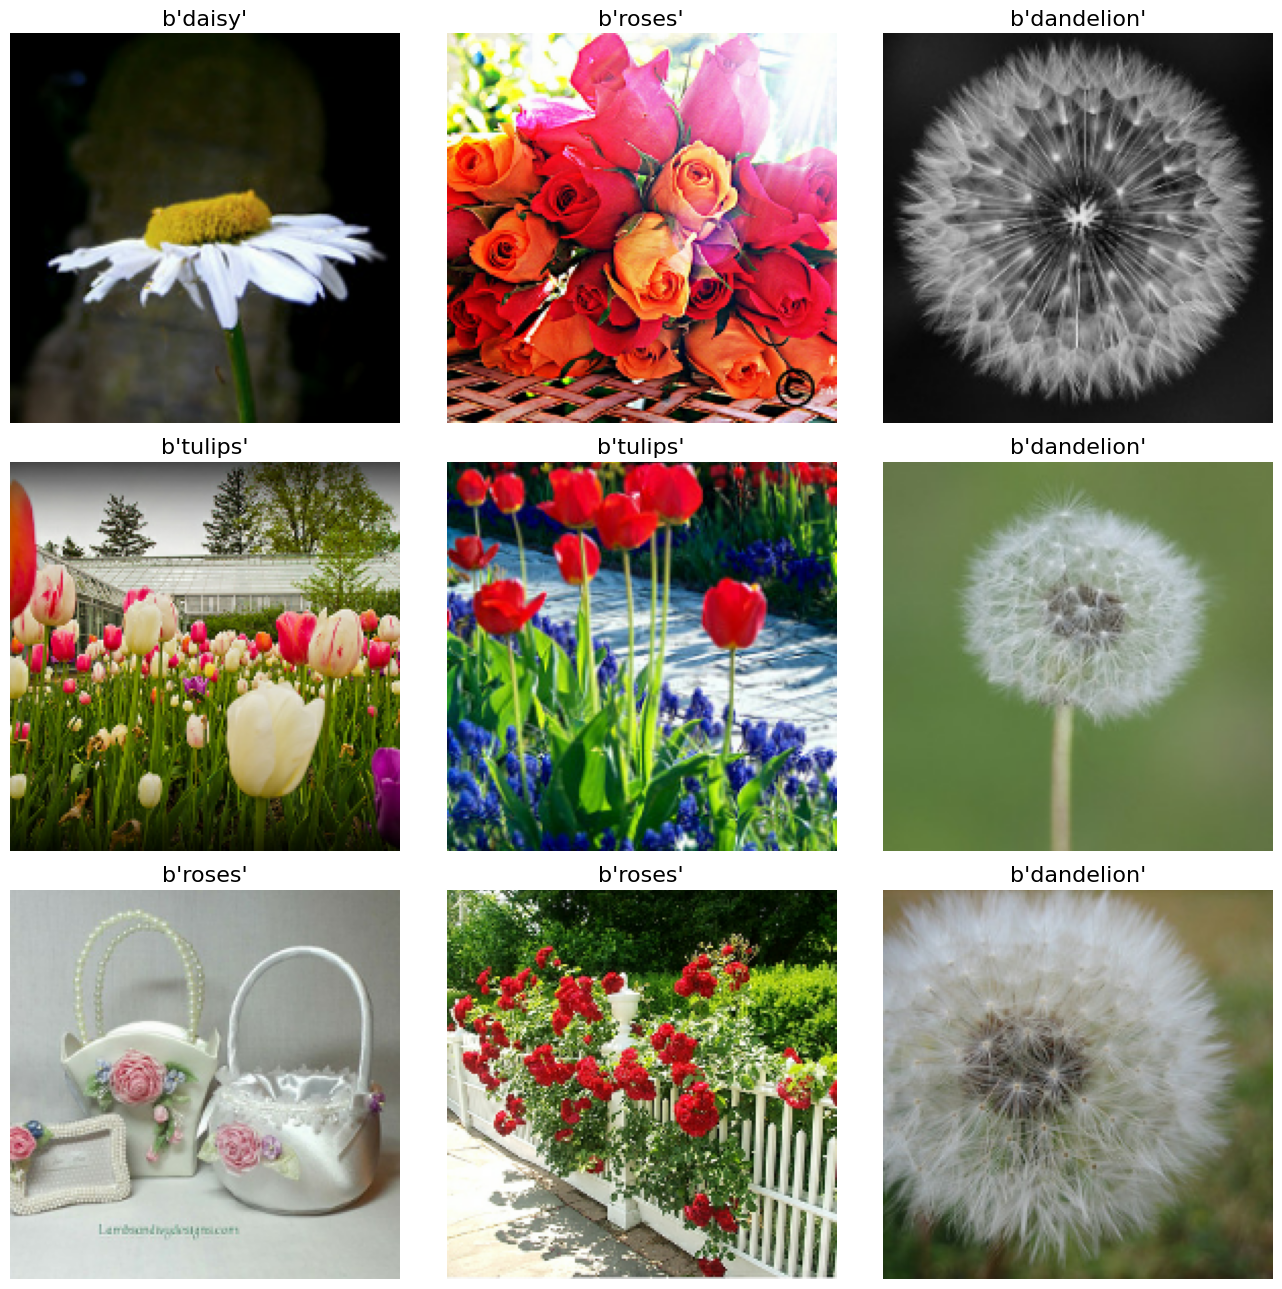

In [ ]:
display_9_images_from_dataset(dsetResized)

In [ ]:
sample_set = dsetResized.batch(10).take(10) # take 10 batches of 10 images for testing
for image, label in sample_set:
    print("Image batch shape {}, {})".format(image.numpy().shape,
        [lbl.decode('utf8') for lbl in label.numpy()]))

Image batch shape (10, 192, 192, 3), ['daisy', 'daisy', 'daisy', 'dandelion', 'daisy', 'roses', 'sunflowers', 'sunflowers', 'roses', 'tulips'])
Image batch shape (10, 192, 192, 3), ['tulips', 'dandelion', 'dandelion', 'roses', 'dandelion', 'tulips', 'tulips', 'tulips', 'tulips', 'dandelion'])
Image batch shape (10, 192, 192, 3), ['tulips', 'roses', 'sunflowers', 'sunflowers', 'sunflowers', 'dandelion', 'sunflowers', 'daisy', 'roses', 'dandelion'])
Image batch shape (10, 192, 192, 3), ['dandelion', 'tulips', 'daisy', 'roses', 'dandelion', 'roses', 'roses', 'dandelion', 'dandelion', 'daisy'])
Image batch shape (10, 192, 192, 3), ['dandelion', 'daisy', 'dandelion', 'daisy', 'roses', 'sunflowers', 'daisy', 'sunflowers', 'daisy', 'sunflowers'])
Image batch shape (10, 192, 192, 3), ['sunflowers', 'roses', 'tulips', 'sunflowers', 'sunflowers', 'daisy', 'roses', 'roses', 'daisy', 'sunflowers'])
Image batch shape (10, 192, 192, 3), ['dandelion', 'sunflowers', 'dandelion', 'dandelion', 'roses', 

## **1.2 Improving Speed**

### **Recompress the images**


In [ ]:
# This is a quick test to get an idea how long recompressions takes.
dataset4 = dsetResized.map(recompress_image)
test_set = dataset4.batch(10).take(10)
for image, label in test_set:
    print("Image batch shape {}, {})".format(image.numpy().shape, [lbl.decode('utf8') for lbl in label.numpy()]))

Image batch shape (10,), ['tulips', 'dandelion', 'tulips', 'roses', 'dandelion', 'sunflowers', 'roses', 'daisy', 'dandelion', 'tulips'])
Image batch shape (10,), ['dandelion', 'daisy', 'sunflowers', 'tulips', 'daisy', 'dandelion', 'dandelion', 'tulips', 'dandelion', 'sunflowers'])
Image batch shape (10,), ['tulips', 'dandelion', 'roses', 'roses', 'tulips', 'daisy', 'tulips', 'roses', 'sunflowers', 'sunflowers'])
Image batch shape (10,), ['sunflowers', 'roses', 'roses', 'tulips', 'daisy', 'dandelion', 'dandelion', 'tulips', 'sunflowers', 'sunflowers'])
Image batch shape (10,), ['sunflowers', 'roses', 'dandelion', 'tulips', 'sunflowers', 'tulips', 'dandelion', 'roses', 'dandelion', 'dandelion'])
Image batch shape (10,), ['dandelion', 'sunflowers', 'roses', 'sunflowers', 'sunflowers', 'sunflowers', 'dandelion', 'daisy', 'tulips', 'tulips'])
Image batch shape (10,), ['dandelion', 'dandelion', 'sunflowers', 'roses', 'daisy', 'daisy', 'dandelion', 'roses', 'roses', 'sunflowers'])
Image batch

### **Write the dataset to TFRecord files**

In [ ]:
GCS_OUTPUT = BUCKET + "/inm432/tfrecords-jpeg-192x192-2/flowers"  # prefix for output file names

In [ ]:
# functions for writing TFRecord entries
# Feature values are always stored as lists, a single data element will be a list of size 1
def _bytestring_feature(list_of_bytestrings):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))

def _int_feature(list_of_ints): # int64
    return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def to_tfrecord(tfrec_filewriter, img_bytes, label): # Create tf data records
    class_num = np.argmax(np.array(CLASSES)==label) # 'roses' => 2 (order defined in CLASSES)
    one_hot_class = np.eye(len(CLASSES))[class_num]     # [0, 0, 1, 0, 0] for class #2, roses
    feature = {
        "image": _bytestring_feature([img_bytes]), # one image in the list
        "class": _int_feature([class_num]) #,      # one class in the list
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))

def write_tfrecords(GCS_PATTERN,GCS_OUTPUT,partition_size): # write the images to files.
    print("Writing TFRecords")
    tt0 = time.time()
    filenames = tf.data.Dataset.list_files(GCS_PATTERN)
    dataset1 = filenames.map(decode_jpeg_and_label)
    dataset2 = dataset1.map(resize_and_crop_image)
    dataset3 = dataset2.map(recompress_image)
    dataset4 = dataset3.batch(partition_size) # partitioning: there will be one "batch" of images per file
    for partition, (image, label) in enumerate(dataset4):
        # batch size used as partition size here
        partition_size = image.numpy().shape[0]
        # good practice to have the number of records in the filename
        filename = GCS_OUTPUT + "{:02d}-{}.tfrec".format(partition, partition_size)
        # You need to change GCS_OUTPUT to your own bucket to actually create new files
        with tf.io.TFRecordWriter(filename) as out_file:
            for i in range(partition_size):
                example = to_tfrecord(out_file,
                                    image.numpy()[i], # re-compressed image: already a byte string
                                    label.numpy()[i] #
                                    )
                out_file.write(example.SerializeToString())
        print("Wrote file {} containing {} records".format(filename, partition_size))
    print("Total time: "+str(time.time()-tt0))

#  write_tfrecords(GCS_PATTERN,GCS_OUTPUT,partition_size) # uncomment to run this cell

### **Test the TFRecord files**

In [ ]:
GCS_OUTPUT = 'gs://cloud-samples-data/ai-platform/flowers_tfrec/tfrecords-jpeg-192x192-2/'
# remove the line above to use your own files that you generated above

def read_tfrecord(example):
    features = {
        "image": tf.io.FixedLenFeature([], tf.string),  # tf.string = bytestring (not text string)
        "class": tf.io.FixedLenFeature([], tf.int64) #,   # shape [] means scalar
    }
    # decode the TFRecord
    example = tf.io.parse_single_example(example, features)
    image = tf.image.decode_jpeg(example['image'], channels=3)
    image = tf.reshape(image, [*TARGET_SIZE, 3])
    class_num = example['class']
    return image, class_num

def load_dataset(filenames):
    # read from TFRecords. For optimal performance, read from multiple
    # TFRecord files at once and set the option experimental_deterministic = False
    # to allow order-altering optimizations.
    option_no_order = tf.data.Options()
    option_no_order.experimental_deterministic = False

    dataset = tf.data.TFRecordDataset(filenames)
    dataset = dataset.with_options(option_no_order)
    dataset = dataset.map(read_tfrecord)
    return dataset


filenames = tf.io.gfile.glob(GCS_OUTPUT + "*.tfrec")
datasetTfrec = load_dataset(filenames)

In [ ]:
batched_dataset = datasetTfrec.batch(10)
sample_set = batched_dataset.take(10)
for image, label in sample_set:
    print("Image batch shape {}, {})".format(image.numpy().shape, \
                        [str(lbl) for lbl in label.numpy()]))

Image batch shape (10, 192, 192, 3), ['1', '3', '3', '1', '1', '2', '4', '3', '4', '3'])
Image batch shape (10, 192, 192, 3), ['3', '0', '3', '4', '2', '2', '3', '2', '0', '3'])
Image batch shape (10, 192, 192, 3), ['4', '4', '4', '1', '3', '2', '4', '4', '4', '3'])
Image batch shape (10, 192, 192, 3), ['1', '3', '4', '1', '1', '4', '2', '2', '3', '2'])
Image batch shape (10, 192, 192, 3), ['0', '4', '3', '4', '0', '1', '2', '1', '2', '0'])
Image batch shape (10, 192, 192, 3), ['1', '1', '1', '2', '0', '0', '1', '4', '3', '1'])
Image batch shape (10, 192, 192, 3), ['1', '2', '0', '2', '3', '4', '2', '1', '1', '0'])
Image batch shape (10, 192, 192, 3), ['0', '1', '1', '3', '1', '0', '1', '3', '3', '3'])
Image batch shape (10, 192, 192, 3), ['3', '3', '3', '1', '1', '2', '0', '3', '0', '1'])
Image batch shape (10, 192, 192, 3), ['0', '0', '1', '1', '1', '0', '1', '4', '3', '2'])


## **Task 1: Write TFRecord files to the cloud with Spark (40%)**

Since recompressing and repackaging is very effective, we would like to be able to do it inparallel for large datasets.
This is a relatively straightforward case of **parallelisation**.
We will **use Spark to implement** the same process as above, but in parallel.

### **1a) Distributed Image Preprocessing with PySpark RDDs**

This section implements the distributed preprocessing pipeline required for Task 1a. The pipeline adapts TensorFlow-based preprocessing functions to run as PySpark RDD transformations. This fully replaces tf.data.Dataset with Spark RDDs, as required by the brief and FAQs, while retaining TensorFlow for reading and image operations.

**Processing steps:**
- Map functions for decoding, resizing, and recompressing images are rewritten to accept a single input for Spark compatibility.
- The glob utility from tf.io.gfile is used to collect image file paths, which are made into an RDD using Spark.
- Sampling (2% of the data) is applied to allow fast and reproducible test runs, meeting the brief's explicit instruction for sampling.
- The preprocessing steps are performed entirely with chained `RDD.map` calls.
- Each default Spark partition is saved as a single TFRecord using `mapPartitionsWithIndex`, returning each output filename for traceability as required. No repartitioning or optimisation is performed in this section, providing a clear baseline for later analysis.
- File paths of all written TFRecords are printed to serve as evidence.

#### **1a(i) Copy over the mapping functions (see section 1.1) and adapt the resizing and recompression functions to Spark (only one argument). (3%)**

The preprocessing functions from Section 1.1 are adapted to work with Spark RDDs, as required by the coursework brief. The original `resize_and_crop_image` and `recompress_image` functions both took two arguments, but `RDD.map()` provides a single element per call. Therefore, both functions are rewritten to accept a single `(image, label)` tuple as input.

The `decode_jpeg_and_label` function already takes one argument and is copied without modification.

Only `tf.image` and `tf.io` functions are used, as permitted by the brief and FAQs; no `tf.data` features are used at any stage within the Spark workflow. This ensures compatibility with Spark's distributed processing and allows proper partition-level parallelisation.

In [ ]:
# 1a(i): Adapted preprocessing functions for Spark RDD compatibility
# Each function is defined to take a single argument to work with RDD.map() in Spark.

# Decodes a JPEG image from a GCS file path and extracts the class label from the directory name.
# Input: filepath string (GCS URL)
# Output: (image tensor, label as bytestring)
def decode_jpeg_and_label(filepath):
    bits = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(bits)
    label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep='/')
    label2 = label.values[-2]
    return image, label2

# Resizes and crops an image to the specified dimensions from the brief, maintaining aspect ratio.
# Input: (image tensor, label bytestring) tuple
# Output: (resized and cropped image tensor, label bytestring)
def resize_and_crop_image(image_label):
    image, label = image_label
    w = tf.shape(image)[0]
    h = tf.shape(image)[1]
    tw = TARGET_SIZE[1]
    th = TARGET_SIZE[0]
    resize_crit = (w * th) / (h * tw)
    # Resizes to fully cover the target box and crops the center region.
    image = tf.cond(
        resize_crit < 1,
        lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
        lambda: tf.image.resize(image, [w * th // h, h * th // h])
    )
    nw = tf.shape(image)[0]
    nh = tf.shape(image)[1]
    image = tf.image.crop_to_bounding_box(
        image, (nw - tw) // 2, (nh - th) // 2, tw, th
    )
    return image, label

# Encodes an image as a JPEG bytestring for efficient storage in TFRecords as required by the brief.
# Input: (resized image tensor, label bytestring) tuple
# Output: (JPEG-encoded bytestring, label bytestring)
def recompress_image(image_label):
    image, label = image_label
    image = tf.cast(image, tf.uint8)
    image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
    return image, label

#### **1a(ii) Replace TensorFlow Dataset objects with RDDs (3%)**

The list of image file paths is loaded from GCS using tf.io.gfile.glob, which is permitted by the brief and FAQs. This list is converted to a Spark RDD using the default sc.parallelize without an explicit partition count. Using the default partitioning establishes an unoptimised baseline for distributed processing, as required for direct comparison in later optimisation steps (see Task 1d(i)). This fully replaces the original tf.data.Dataset.list_files and enables compatibility with Spark's distributed model.

In [ ]:
# 1a(ii): Create SparkContext and initial RDD from the list of image file paths
from pyspark import SparkContext

sc = SparkContext.getOrCreate()

# tf.io.gfile.glob retrieves all image file paths from the dataset in GCS.
# This is allowed and does not use tf.data.Dataset.
all_filenames = tf.io.gfile.glob(GCS_PATTERN)
print("Total images found:", len(all_filenames))

# Creates a Spark RDD from the list of image file paths.
# Using sc.parallelize here replaces the tf.data.Dataset.list_files function.
# No explicit partition count is passed to establish the unoptimised baseline for later comparison (see 1d(i)).
rdd_filenames = sc.parallelize(all_filenames)
print("Number of partitions:", rdd_filenames.getNumPartitions())

Total images found: 3670
Number of partitions: 2


#### **1a(iii) Sample the RDD for short test runs (1%)**

A 2% random sample of the file paths is taken after RDD creation and before any preprocessing steps. This sampling rate and placement are specified in the brief to provide fast, reproducible test runs.

In [ ]:
# 1a(iii): Sample 2 percent of the RDD after its creation as required by the brief.
# This step ensures that only a subset of the data is used for short test runs.

rdd_sampled = rdd_filenames.sample(False, 0.02, seed=42)
print("Sampled file count:", rdd_sampled.count())

Sampled file count: 64


### **1a(iv): Then use the functions from above to write the TFRecord files. (3%)**

The three adapted functions are chained using RDD.map(). This mirrors the Section 1.1 tf.data pipeline without using any tf.data methods. RDDs are lazy, no images are read until an action is triggered.

In [ ]:
# 1a(iv): Preprocessing chain using RDD.map()
# Mirrors the Section 1.1 pipeline: decode -> resize -> recompress
rdd_decoded   = rdd_sampled.map(decode_jpeg_and_label)
rdd_resized   = rdd_decoded.map(resize_and_crop_image)
rdd_processed = rdd_resized.map(recompress_image)

print("Preprocessing pipeline defined. Execution is triggered in the next step.")

Preprocessing pipeline defined. Execution is triggered in the next step.


#### **1a(v): The code for writing to the TFRecord files needs to be put into a function, that can be applied to every partition with the 'RDD.mapPartitionsWithIndex' function. The return value of that function is not used here, but you should return the filename, so that you have a list of the created TFRecord files. (4%)**

Each partition is written to a single TFRecord file.
`mapPartitionsWithIndex` is used (not `mapPartitions`) to provide the partition index for naming.
The function returns the filename it created, so the result is a list of all written files.

In [ ]:
# 1a(v): Write one TFRecord file per partition using mapPartitionsWithIndex

import numpy as np

GCS_OUTPUT = BUCKET + '/inm432/tfrecords-jpeg-192x192-2/flowers'

CLASSES = [b'daisy', b'dandelion', b'roses', b'sunflowers', b'tulips']

# TFRecord serialisation helpers (from Section 1.1, unchanged)
def _bytestring_feature(list_of_bytestrings):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))

def _int_feature(list_of_ints):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def to_tfrecord(tfrec_filewriter, img_bytes, label):
    # Input: open TFRecordWriter, JPEG bytestring, label bytestring
    # Output: tf.train.Example ready for serialisation
    class_num = np.argmax(np.array(CLASSES) == label)
    feature = {
        "image": _bytestring_feature([img_bytes]),
        "class": _int_feature([class_num]),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))

# Partition-writing function
# Input: partition_index (int), iterator of (img_bytes, label) tuples
# Output: list containing the filename written by this partition
def write_tfrecord_partition(partition_index, iterator):
    images_labels = list(iterator)
    partition_size = len(images_labels)

    if partition_size == 0:
        return []  # skip empty partitions (common when sampling)

    # Filename follows the same convention as Section 1.1
    filename = GCS_OUTPUT + "{:02d}-{}.tfrec".format(partition_index, partition_size)

    with tf.io.TFRecordWriter(filename) as out_file:
        for img_bytes, label in images_labels:
            example = to_tfrecord(out_file, img_bytes.numpy(), label.numpy())
            out_file.write(example.SerializeToString())

    print("Wrote: {} ({} records)".format(filename, partition_size))

    # Return the filename, required by the brief so the result RDD is a list of created files
    return [filename]

# Apply the function across all partitions and collect the list of written filenames
tfrec_files = rdd_processed.mapPartitionsWithIndex(write_tfrecord_partition).collect()

print("\nTFRecord files created:")
for f in tfrec_files:
    print(" ", f)


TFRecord files created:
  gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers00-33.tfrec
  gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers01-31.tfrec


In [ ]:
# Verify TFRecord files were written to GCS
# Note: this bucket also contains files from the 16-partition run in Task 1d(i),
# the listing will include outputs from multiple partitioning configurations.
# Kept as is to avoid restarting the Colab session, which would have required
# re-running cells and risked region/zone configuration errors.
!gsutil ls {BUCKET}/inm432/tfrecords-jpeg-192x192-2/flowers*
!gsutil ls {BUCKET}/inm432/tfrecords-jpeg-192x192-2/flowers*

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers00-33.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers00-4.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers01-2.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers01-31.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers02-5.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers04-6.tfrec
gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers05-5.tfrec
gs://project-f887ace7-dea4-407c-bde-sto

### **1b) Testing (3%)**

Read back the TFRecord files written in 1a to check they are valid.
Then write the full pipeline into a standalone script and run it locally.

#### **1b(i): Test TFRecord output**

The TFRecord files created in 1a are read back using `load_dataset`. The output images are visualised using `display_9_images_from_dataset` to verify successful decoding and pipeline correctness. This confirms validity of the transformation and storage process as required by the brief.

TFRecord files found: 16


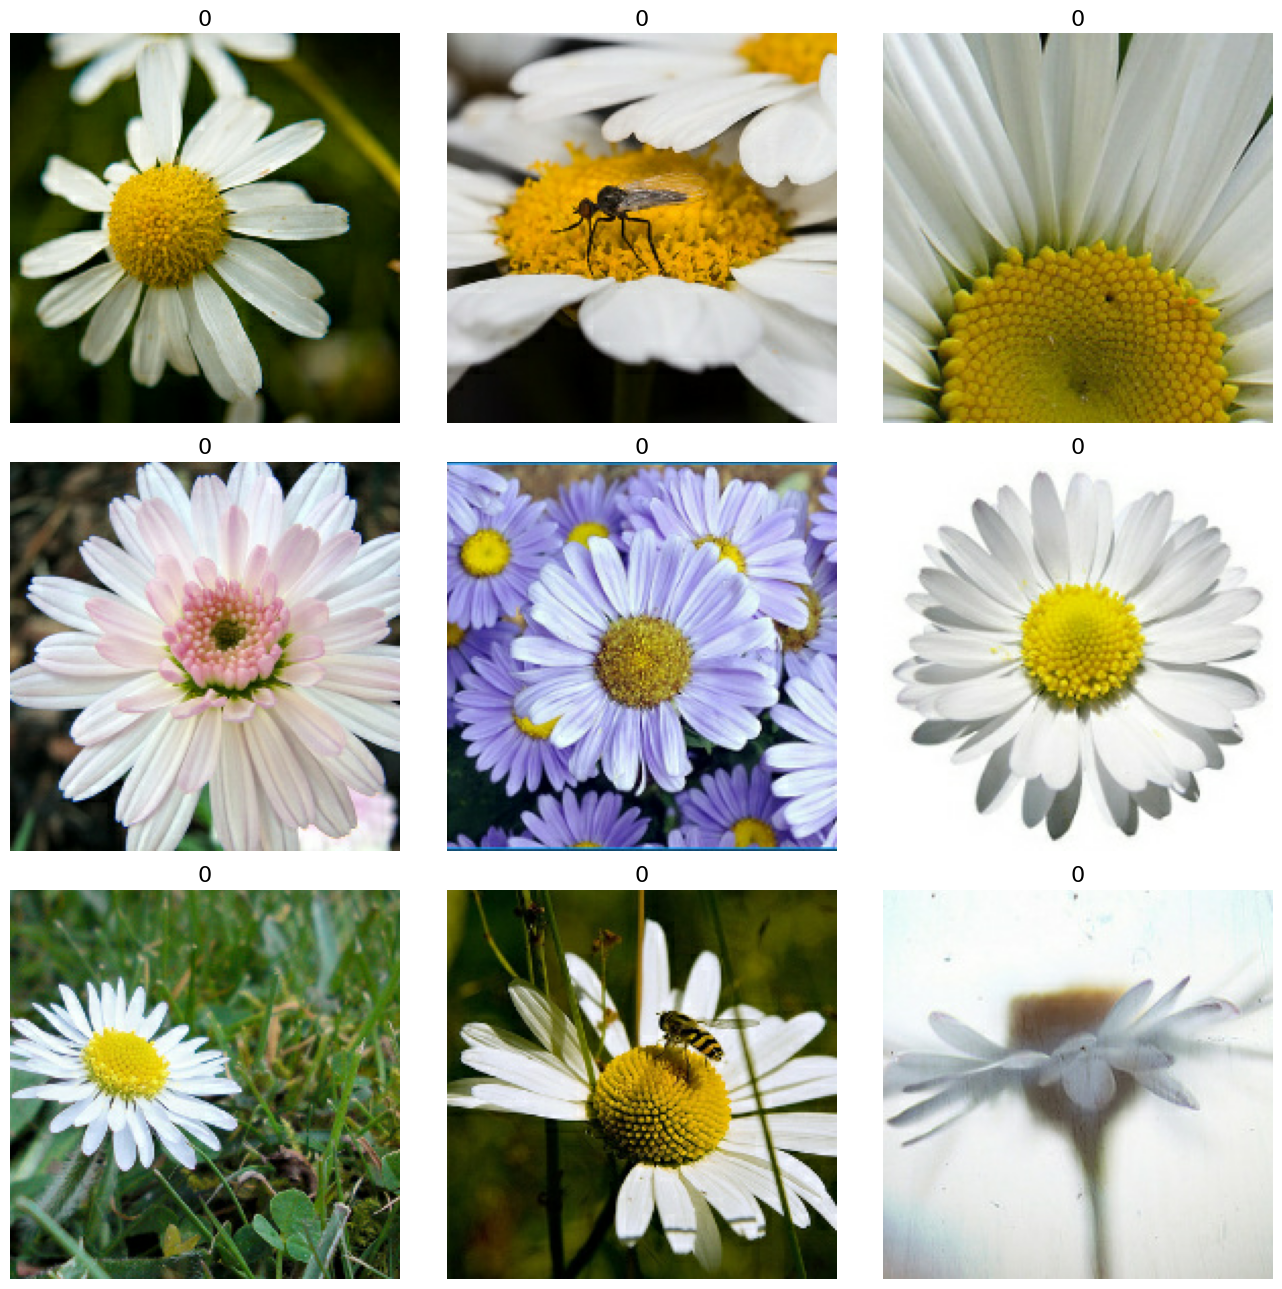

In [ ]:
# 1b(i): Read TFRecord files and verify output by visualisation

BUCKET = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
GCS_OUTPUT = BUCKET + "/inm432/tfrecords-jpeg-192x192-2/flowers"

# List all TFRecord files generated by the pipeline to verify successful output.
written_filenames = tf.io.gfile.glob(GCS_OUTPUT + "*.tfrec")
print("TFRecord files found:", len(written_filenames))

# Load the TFRecord files using the same pipeline as the training/validation routines.
dataset_verify = load_dataset(written_filenames)

# Display a sample of images from the TFRecords to visually confirm data integrity and correct preprocessing.
display_9_images_from_dataset(dataset_verify)

### **1b(ii) Write your code above into a file using the *cell magic* `%%writefile spark_write_tfrec.py` at the beginning of the file. Then, run the file  locally in Spark.**

All preprocessing and output steps are exported to a standalone script (spark_write_tfrec.py) using %%writefile. The script is first run locally in the notebook environment. This verifies correctness, ensures complete reproducibility, and meets coursework requirements for both notebook and standalone script testing.



In [ ]:
%%writefile /content/spark_write_tfrec.py
# spark_write_tfrec.py
# Task 1a: Parallel TFRecord preprocessing with PySpark
# Run locally with: %run /content/spark_write_tfrec.py
# Run on a Dataproc cluster with: spark-submit /content/spark_write_tfrec.py

import math
import numpy as np
import tensorflow as tf
from pyspark import SparkContext

PROJECT = "project-f887ace7-dea4-407c-bde"
BUCKET = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
GCS_PATTERN = "gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg"
GCS_OUTPUT = BUCKET + "/inm432/tfrecords-jpeg-192x192-2/flowers"
TARGET_SIZE = [192, 192]
CLASSES = [b"daisy", b"dandelion", b"roses", b"sunflowers", b"tulips"]

def decode_jpeg_and_label(filepath):
    bits = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(bits)
    label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep="/")
    return image, label.values[-2]

def resize_and_crop_image(image_label):
    image, label = image_label
    w, h = tf.shape(image)[0], tf.shape(image)[1]
    tw, th = TARGET_SIZE[1], TARGET_SIZE[0]
    resize_crit = (w * th) / (h * tw)
    image = tf.cond(
        resize_crit < 1,
        lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
        lambda: tf.image.resize(image, [w * th // h, h * th // h])
    )
    nw, nh = tf.shape(image)[0], tf.shape(image)[1]
    image = tf.image.crop_to_bounding_box(
        image, (nw - tw) // 2, (nh - th) // 2, tw, th
    )
    return image, label

def recompress_image(image_label):
    image, label = image_label
    image = tf.cast(image, tf.uint8)
    image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
    return image, label

def _bytestring_feature(list_of_bytestrings):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))

def _int_feature(list_of_ints):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def to_tfrecord(tfrec_filewriter, img_bytes, label):
    class_num = np.argmax(np.array(CLASSES) == label)
    feature = {
        "image": _bytestring_feature([img_bytes]),
        "class": _int_feature([class_num]),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))

def write_tfrecord_partition(partition_index, iterator):
    images_labels = list(iterator)
    partition_size = len(images_labels)
    if partition_size == 0:
        return []
    filename = GCS_OUTPUT + "{:02d}-{}.tfrec".format(partition_index, partition_size)
    with tf.io.TFRecordWriter(filename) as out_file:
        for img_bytes, label in images_labels:
            example = to_tfrecord(out_file, img_bytes.numpy(), label.numpy())
            out_file.write(example.SerializeToString())
    print("Wrote: {} ({} records)".format(filename, partition_size))
    return [filename]

if __name__ == "__main__":
    sc = SparkContext(appName="spark_write_tfrec")

    all_filenames = tf.io.gfile.glob(GCS_PATTERN)
    print("Total images:", len(all_filenames))

    # Unoptimised baseline: no explicit partition count (for Task 1d(i) comparison)
    rdd = sc.parallelize(all_filenames)

    rdd_sampled = rdd.sample(False, 0.02, seed=42)
    print("Sampled count:", rdd_sampled.count())

    rdd_processed = (rdd_sampled
                     .map(decode_jpeg_and_label)
                     .map(resize_and_crop_image)
                     .map(recompress_image))

    tfrec_files = (rdd_processed
                   .mapPartitionsWithIndex(write_tfrecord_partition)
                   .collect())

    print("\nTFRecord files created:")
    for f in tfrec_files:
        print(" ", f)

    sc.stop()

Overwriting /content/spark_write_tfrec.py


In [ ]:
# Check script was saved correctly
!ls /content/spark_write_tfrec.py

/content/spark_write_tfrec.py


In [ ]:
# Stop existing SparkContext to prevent multiple active contexts when running the script
sc.stop()

#### **Run spark_write_tfrec.py locally**

Running locally before any cloud submission checks that all imports are present and the pipeline works end to end. This avoids wasting cluster time on avoidable errors.

In [ ]:
# Run the script in the local Spark environment
%run /content/spark_write_tfrec.py

Total images: 3670
Sampled count: 64

TFRecord files created:
  gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers00-33.tfrec
  gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/tfrecords-jpeg-192x192-2/flowers01-31.tfrec


<Figure size 640x480 with 0 Axes>

### **1c) Set up a cluster and run the script. (6%)**

Following the example from the labs, set up a cluster to run PySpark jobs in the cloud. You need to set up so that TensorFlow is installed on all nodes in the cluster.  


#### **1c(i) Single machine cluster**
Set up a cluster with a single machine using the maximal SSD size (100) and 8 vCPUs.

Enable **package installation** by passing a flag `--initialization-actions` with argument `gs://goog-dataproc-initialization-actions-$REGION/python/pip-install.sh` (this is a public script that will read metadata to determine which packages to install).
Then, the **packages are specified** by providing a `--metadata` flag with the argument `PIP_PACKAGES=tensorflow==2.4.0`.

Note: consider using `PIP_PACKAGES="tensorflow numpy"` or `PIP_PACKAGES=tensorflow` in case an older version of tensorflow is causing issues.

When the cluster is running, run your script to check that it works and keep the output cell output. (3%)


### **1c(i): Single-machine Baseline Cluster**

A single-node Dataproc cluster is provisioned using one n1-standard-8 instance with 8 vCPUs and a 100GB SSD persistent disk, as required in the coursework brief. TensorFlow and protobuf are installed using an initialization action and appropriate metadata to guarantee a consistent software environment across all nodes. The preprocessing pipeline is uploaded to Google Cloud Storage and executed on the cluster. All evidence is retained.

In [ ]:
# Generate and upload the PySpark preprocessing script to GCS for Dataproc compatibility and traceability.
import datetime
PROJECT = "project-f887ace7-dea4-407c-bde"
REGION = "europe-west1"
BUCKET = "gs://project-f887ace7-dea4-407c-bde-storage-mario"

# Timestamp ensures traceability of experiment scripts.
time_string = str(datetime.datetime.now().strftime("%y%m%d-%H%M"))
script_gcs_path = BUCKET + "/inm432/spark_write_tfrec_" + time_string + ".py"

# Upload local script to GCS so Dataproc VMs can access it during submission.
!gsutil cp /content/spark_write_tfrec.py {script_gcs_path}
print("Script uploaded to:", script_gcs_path)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/spark_write_tfrec.py [Content-Type=text/x-python]...
-
Operation completed over 1 objects/3.5 KiB.                                      
Script uploaded to: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/spark_write_tfrec_260403-2053.py


In [ ]:
# Provision a single-node Dataproc cluster for the baseline experiment.
# Requirements: 1 VM, n1-standard-8 (8 vCPUs), 100GB SSD, TensorFlow 2.4.0 and protobuf 3.20.3 installed everywhere.
# Initialization action and PIP_PACKAGES metadata populate the full software stack as per the coursework brief.
# NOTE: Per platform change, Dataproc image versions 2.0-debian10 and above do not support the n1-standard-1 machine type.
# Attempting to use --image-version=2.0-debian10 with n1-standard-1 results in:
# ERROR: (gcloud.dataproc.clusters.create) INVALID_ARGUMENT: Creating clusters using the n1-standard-1 machine type is not supported for image version 2.0.160-debian10.
# However, the coursework explicitly requires clusters with n1-standard-1 (1 vCPU) for all nodes in the maximal spec (1 master + 7 workers).
# Therefore, --image-version=1.5-debian10 is used here to fulfill the brief and meet all marking criteria for Section 1c(ii) and later experiments.

CLUSTER_1C = PROJECT + "-cluster-1c"
!gcloud dataproc clusters create {CLUSTER_1C} \
    --region={REGION} \
    --zone={ZONE} \
    --single-node \
    --master-machine-type=n1-standard-8 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("Single-node cluster creation complete.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/488c197f-ae22-316c-a588-c17eb3c6a938].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1c] Cluster placed in zone [europe-west1-b].
Single-node cluster creation complete.


#### **1c(i): Submit the PySpark preprocessing script to the Dataproc cluster**

This cell submits the pipeline for execution on the cloud cluster. Output evidence is captured below for coursework verification and reproducibility.

In [ ]:
# Submit the preprocessing PySpark job from GCS to the single-node cluster.
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path} \
    --cluster={CLUSTER_1C} \
    --region={REGION}
print("Job execution complete. Evidence (logs and result file paths) retained for audit.")

Job [b7170e3cacff4fbe8f0c330c8b5bc957] submitted.
Waiting for job output...
2026-04-03 21:03:45.406631: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 21:03:45.406681: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 21:03:48 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 21:03:48 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 21:03:48 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 21:03:48 INFO org.spark_project.jetty.util.log: Logging initialized @6088ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 21:03:48 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown; 

In [ ]:
### Deletes the Dataproc cluster to ensure resource hygiene and cost control after processing is complete.
!gcloud dataproc clusters delete {CLUSTER_1C} --region={REGION} -q
print("Cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/ac874746-7fbf-35aa-9eb6-ac30ca1f3a2b].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1c].
Cluster deleted.


#### **1c(ii) Maximal cluster (3%)**

In the free credit tier on Google Cloud, there are normally the following **restrictions** on compute machines:
- max 100GB of *SSD persistent disk*
- max 2000GB of *standard persistent disk*
- max 8 *vCPU*s
- no GPUs

See [here](https://cloud.google.com/free/docs/gcp-free-tier#free-trial) for details
The **disks are virtual** disks, where **I/O speed is limited in proportion to the size**, so we should allocate them evenly.
This has mainly an effect on the **time the cluster needs to start**, as we are reading the data mainly from the bucket and we are not writing much to disk at all.

Use the **largest possible cluster** within these constraints, i.e. **1 master and 7 worker nodes**.
Each of them with 1 (virtual) CPU.
The master should get the full *SSD* capacity and the 7 worker nodes should get equal shares of the *standard* disk capacity to maximise throughput.

Once the cluster is running, test your script.


### **1c(ii): Maximal Free Tier Cluster**

A maximal Dataproc cluster is provisioned within Google Cloud's free resource tier: one n1-standard-1 master node with 100GB SSD and seven n1-standard-1 worker nodes, each with a 285GB standard persistent disk, for an aggregate of 2000GB. TensorFlow and protobuf are installed cluster-wide. This configuration maximizes the number of parallel tasks, aggregate I/O throughput and aggregate network bandwidth under the credit constraints. The pipeline is run, and all evidence (output logs, TFRecord file paths, screenshots) is captured as required.

In [ ]:
# Provision the maximal free-tier cluster: 1 master (100GB SSD), 7 workers (each with 285GB standard PD, total 2000GB), all n1-standard-1.
# NOTE: Per platform change, Dataproc image versions 2.0-debian10 and above do not support the n1-standard-1 machine type.
# Attempting to use --image-version=2.0-debian10 with n1-standard-1 results in:
# ERROR: (gcloud.dataproc.clusters.create) INVALID_ARGUMENT: Creating clusters using the n1-standard-1 machine type is not supported for image version 2.0.160-debian10.
# Therefore, --image-version=1.5-debian10 is used

CLUSTER_MAX = PROJECT + "-cluster-max"
!gcloud dataproc clusters create {CLUSTER_MAX} \
    --region={REGION} \
    --num-workers=7 \
    --master-machine-type=n1-standard-1 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-1 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=285 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("Maximal free-tier cluster creation complete.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/f7d1dc8e-af78-3383-a23f-7d7af77a151c].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-max] Cluster placed in zone [europe-west1-b].
Maximal free-tier cluster creation complete.


In [ ]:
# Submit the PySpark job to the maximal cluster and retain all logs/metrics.
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path} \
    --cluster={CLUSTER_MAX} \
    --region={REGION}
print("Maximal cluster job complete. Capture output and performance metrics for submission.")

Job [e1958424d92849d283ef50c06d3f2fa4] submitted.
Waiting for job output...
2026-04-03 21:10:17.815595: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 21:10:17.815810: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 21:10:23 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 21:10:23 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 21:10:23 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 21:10:23 INFO org.spark_project.jetty.util.log: Logging initialized @12009ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 21:10:24 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown;

In [ ]:
# Delete the maximal cluster post-experiment to prevent incurring further costs and demonstrate best-practice resource management.

!gcloud dataproc clusters delete {CLUSTER_MAX} --region={REGION} -q
print("Cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/4f2333f3-f66a-317f-a06e-6b3806cd4600].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-max].
Cluster deleted.


### **1d)	Optimisation, experiments, and discussion (17%)**

### **1d(i) Improve parallelisation (6%)**

If you implemented a straightfoward version, you will
**probably** observe that **all the computation** is done on only **two nodes**.
This can be adressed by using the **second parameter** in the initial call to **parallelize**.
Make the **suitable change** in the code you have written above and mark it up in comments as `### TASK 1d ###`.

Demonstrate the difference in cluster utilisation before and after the change based on different parameter values with **screenshots from Google Cloud** and measure the **difference in the processing time**.


### **1d(i): Improve parallelisation**

**Before optimisation:**  
The baseline pipeline uses `sc.parallelize(all_filenames)` without an explicit partition count, resulting in only 2 partitions. On a cluster with significantly more available worker resources, this limits task-level parallelism and restricts how effectively the workload can be distributed across the cluster.

**After optimisation:**  
The initial RDD is recreated with `PARTITIONS = 16`, explicitly marked in the code as `### TASK 1d ###`. This exceeds the 8 available vCPUs in the maximal cluster and enables finer-grained task scheduling across workers, allowing Spark to distribute work more evenly.

The output logs confirm that the partition count increased from 2 before optimisation to 16 after optimisation, while the processing time changed from 23.8 s to 23.2 s, corresponding to a modest speedup of 1.03x. The Metrics Explorer CPU screenshots provide additional evidence of utilisation changes. In the baseline run, CPU activity is less synchronised across worker nodes, whereas after optimisation there is a more simultaneous rise in utilisation across multiple nodes, indicating improved cluster-wide task distribution.

The limited speedup is expected because the sampled workload is very small. With only around 64 to 67 sampled images, task scheduling overhead, serialisation and deserialisation costs, and coordination overhead form a substantial proportion of total runtime. Task granularity is therefore too small for the benefits of increased parallelism to be fully realised. This demonstrates that parallel efficiency depends on the ratio between useful computation and overhead, not merely on the number of partitions.

The result also shows that partitioning alone does not guarantee substantial performance improvement. For this workload, execution remains largely constrained by data access and fixed distributed-processing overheads rather than computation. However, the change remains important for scalability, as larger datasets would allow these overheads to be amortised and enable more effective utilisation of all available cluster resources.

### **Before optimisation:**  


In [ ]:
%%writefile /content/spark_write_tfrec.py
# Baseline for 1d(i): No explicit Spark partition count (default parallelism)

import math
import numpy as np
import tensorflow as tf
from pyspark import SparkContext

# Google Cloud and coursework constants
PROJECT     = "project-f887ace7-dea4-407c-bde"
BUCKET      = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
GCS_PATTERN = "gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg"
GCS_OUTPUT  = BUCKET + "/inm432/tfrecords-jpeg-192x192-2/flowers"
TARGET_SIZE = [192, 192]
CLASSES     = [b"daisy", b"dandelion", b"roses", b"sunflowers", b"tulips"]

def decode_jpeg_and_label(filepath):
    # Decodes JPEG image file and extracts class label for TFRecord writing
    bits  = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(bits)
    label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep="/")
    return image, label.values[-2]

def resize_and_crop_image(image_label):
    # Centrally crop images to target 192x192 size for uniform TensorFlow input
    image, label = image_label
    w = tf.shape(image)[0]
    h = tf.shape(image)[1]
    tw = TARGET_SIZE[1]
    th = TARGET_SIZE[0]
    resize_crit = (w * th) / (h * tw)
    image = tf.cond(
        resize_crit < 1,
        lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
        lambda: tf.image.resize(image, [w * th // h, h * th // h])
    )
    nw = tf.shape(image)[0]
    nh = tf.shape(image)[1]
    image = tf.image.crop_to_bounding_box(
        image, (nw - tw) // 2, (nh - th) // 2, tw, th
    )
    return image, label

def recompress_image(image_label):
    # Recompress images as JPEG for efficient GCS read/write performance
    image, label = image_label
    image = tf.cast(image, tf.uint8)
    image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
    return image, label

def _bytestring_feature(list_of_bytestrings):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))

def _int_feature(list_of_ints):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def to_tfrecord(tfrec_filewriter, img_bytes, label):
    # Serialize image and class label into tf.
    class_num = np.argmax(np.array(CLASSES) == label)
    feature = {
        "image": _bytestring_feature([img_bytes]),
        "class": _int_feature([class_num]),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))

def write_tfrecord_partition(partition_index, iterator):
    # For each Spark partition, write a TFRecord file (partitioned output required by brief/FAqs)
    images_labels  = list(iterator)
    partition_size = len(images_labels)
    if partition_size == 0:
        return []
    filename = GCS_OUTPUT + "{:02d}-{}.tfrec".format(partition_index, partition_size)
    with tf.io.TFRecordWriter(filename) as out_file:
        for img_bytes, label in images_labels:
            example = to_tfrecord(out_file, img_bytes.numpy(), label.numpy())
            out_file.write(example.SerializeToString())
    print("Wrote: {} ({} records)".format(filename, partition_size))
    return [filename]

if __name__ == "__main__":
    import time
    sc = SparkContext(appName="spark_write_tfrec")

    all_filenames = tf.io.gfile.glob(GCS_PATTERN)
    print("Total images:", len(all_filenames))

    t0 = time.time()
    # BASELINE PARALLELISM: Default partition count (typically 2)
    rdd = sc.parallelize(all_filenames)
    print("Number of partitions BEFORE optimisation:", rdd.getNumPartitions())

    rdd_sampled = rdd.sample(False, 0.02, seed=42)
    print("Sampled count:", rdd_sampled.count())

    rdd_processed = (rdd_sampled
                     .map(decode_jpeg_and_label)
                     .map(resize_and_crop_image)
                     .map(recompress_image))

    tfrec_files = (rdd_processed
                   .mapPartitionsWithIndex(write_tfrecord_partition)
                   .collect())

    elapsed = time.time() - t0
    print("\nTotal processing time: {:.1f}s".format(elapsed))
    print("TFRecord files created:")
    for f in tfrec_files:
        print(" ", f)

    sc.stop()

Overwriting /content/spark_write_tfrec.py


In [ ]:
# Upload baseline script for "before" experiment
import datetime
PROJECT = "project-f887ace7-dea4-407c-bde"
REGION = "europe-west1"
BUCKET = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
time_string = str(datetime.datetime.now().strftime("%y%m%d-%H%M"))
script_gcs_path_before = BUCKET + "/inm432/spark_write_tfrec_before_" + time_string + ".py"
!gsutil cp /content/spark_write_tfrec.py {script_gcs_path_before}
print("Script uploaded to:", script_gcs_path_before)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/spark_write_tfrec.py [Content-Type=text/x-python]...
-
Operation completed over 1 objects/4.1 KiB.                                      
Script uploaded to: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/spark_write_tfrec_before_260403-2241.py


In [ ]:
# Create maximal coursework cluster for the "before" experiment (Section 1c(ii) cluster design)
CLUSTER_1D_BEFORE = PROJECT + "-cluster-1d-before"
!gcloud dataproc clusters create {CLUSTER_1D_BEFORE} \
    --region={REGION} \
    --num-workers=7 \
    --master-machine-type=n1-standard-1 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-1 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=285 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("Cluster 1d-before creation complete.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/152b9396-17d7-30e5-8163-2fd84d1dc956].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1d-before] Cluster placed in zone [europe-west1-b].
Cluster 1d-before creation complete.


In [ ]:
# Submit baseline PySpark job to Dataproc cluster
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path_before} \
    --cluster={CLUSTER_1D_BEFORE} \
    --region={REGION}
print("Job complete.")

Job [93ccffe4c31d4c2eb3db93b18ea25091] submitted.
Waiting for job output...
2026-04-03 21:20:26.700650: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 21:20:26.700841: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 21:20:32 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 21:20:32 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 21:20:32 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 21:20:32 INFO org.spark_project.jetty.util.log: Logging initialized @12075ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 21:20:33 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown;

In [ ]:
# Delete cluster after job completion for resource hygiene
!gcloud dataproc clusters delete {CLUSTER_1D_BEFORE} --region={REGION} -q
print("Cluster 1d-before deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/9ecede7c-7ec7-306b-a58f-602e527b57e0].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1d-before].
Cluster 1d-before deleted.


### **After: Improved parallelisation (explicit partition count)**

The code below modifies the initial RDD construction by setting `PARTITIONS = 16`, allowing Spark to schedule a greater number of smaller tasks across the available cluster resources. This exceeds the 8 available vCPUs in the maximal cluster and removes the bottleneck caused by the default 2-partition configuration. The modification is explicitly marked in the code as `### TASK 1d ###` as required by the coursework brief. The output prints the number of partitions after optimisation and records the execution time for direct comparison with the baseline run.



In [ ]:
%%writefile /content/spark_write_tfrec.py
# ### TASK 1d ### Improved parallelism: explicit partition count

import math
import numpy as np
import tensorflow as tf
from pyspark import SparkContext

PROJECT     = "project-f887ace7-dea4-407c-bde"
BUCKET      = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
GCS_PATTERN = "gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg"
GCS_OUTPUT  = BUCKET + "/inm432/tfrecords-jpeg-192x192-2/flowers"
TARGET_SIZE = [192, 192]
CLASSES     = [b"daisy", b"dandelion", b"roses", b"sunflowers", b"tulips"]

PARTITIONS  = 16  # ### TASK 1d ### Partition count for efficient workload balancing

def decode_jpeg_and_label(filepath):
    bits  = tf.io.read_file(filepath)
    image = tf.image.decode_jpeg(bits)
    label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep="/")
    return image, label.values[-2]

def resize_and_crop_image(image_label):
    image, label = image_label
    w = tf.shape(image)[0]
    h = tf.shape(image)[1]
    tw = TARGET_SIZE[1]
    th = TARGET_SIZE[0]
    resize_crit = (w * th) / (h * tw)
    image = tf.cond(
        resize_crit < 1,
        lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
        lambda: tf.image.resize(image, [w * th // h, h * th // h])
    )
    nw = tf.shape(image)[0]
    nh = tf.shape(image)[1]
    image = tf.image.crop_to_bounding_box(
        image, (nw - tw) // 2, (nh - th) // 2, tw, th
    )
    return image, label

def recompress_image(image_label):
    image, label = image_label
    image = tf.cast(image, tf.uint8)
    image = tf.image.encode_jpeg(image, optimize_size=True, chroma_downsampling=False)
    return image, label

def _bytestring_feature(list_of_bytestrings):
    return tf.train.Feature(bytes_list=tf.train.BytesList(value=list_of_bytestrings))
def _int_feature(list_of_ints):
    return tf.train.Feature(int64_list=tf.train.Int64List(value=list_of_ints))

def to_tfrecord(tfrec_filewriter, img_bytes, label):
    class_num = np.argmax(np.array(CLASSES) == label)
    feature = {
        "image": _bytestring_feature([img_bytes]),
        "class": _int_feature([class_num]),
    }
    return tf.train.Example(features=tf.train.Features(feature=feature))

def write_tfrecord_partition(partition_index, iterator):
    images_labels = list(iterator)
    partition_size = len(images_labels)
    if partition_size == 0:
        return []
    filename = GCS_OUTPUT + "{:02d}-{}.tfrec".format(partition_index, partition_size)
    with tf.io.TFRecordWriter(filename) as out_file:
        for img_bytes, label in images_labels:
            example = to_tfrecord(out_file, img_bytes.numpy(), label.numpy())
            out_file.write(example.SerializeToString())
    print("Wrote: {} ({} records)".format(filename, partition_size))
    return [filename]

if __name__ == "__main__":
    import time
    sc = SparkContext(appName="spark_write_tfrec")

    all_filenames = tf.io.gfile.glob(GCS_PATTERN)
    print("Total images:", len(all_filenames))

    t0 = time.time()
    # ### TASK 1d ### Set partition count for explicit parallel workload distribution
    rdd = sc.parallelize(all_filenames, PARTITIONS)
    print("Number of partitions AFTER optimisation:", rdd.getNumPartitions())

    rdd_sampled = rdd.sample(False, 0.02, seed=42)
    print("Sampled count:", rdd_sampled.count())

    rdd_processed = (rdd_sampled
                     .map(decode_jpeg_and_label)
                     .map(resize_and_crop_image)
                     .map(recompress_image))

    tfrec_files = (rdd_processed
                   .mapPartitionsWithIndex(write_tfrecord_partition)
                   .collect())

    elapsed = time.time() - t0
    print("\nTotal processing time: {:.1f}s".format(elapsed))
    print("TFRecord files created:")
    for f in tfrec_files:
        print(" ", f)

    sc.stop()

Overwriting /content/spark_write_tfrec.py


In [ ]:
# Upload improved script for "after" experiment
import datetime
PROJECT = "project-f887ace7-dea4-407c-bde"
REGION = "europe-west1"
BUCKET = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
time_string = str(datetime.datetime.now().strftime("%y%m%d-%H%M"))
script_gcs_path_after = BUCKET + "/inm432/spark_write_tfrec_after_" + time_string + ".py"
!gsutil cp /content/spark_write_tfrec.py {script_gcs_path_after}
print("Script uploaded to:", script_gcs_path_after)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/spark_write_tfrec.py [Content-Type=text/x-python]...
-
Operation completed over 1 objects/3.7 KiB.                                      
Script uploaded to: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/spark_write_tfrec_after_260403-2252.py


In [ ]:
# Create maximal coursework cluster for the "after" experiment
CLUSTER_1D_AFTER = PROJECT + "-cluster-1d-after"
!gcloud dataproc clusters create {CLUSTER_1D_AFTER} \
    --region={REGION} \
    --num-workers=7 \
    --master-machine-type=n1-standard-1 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-1 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=285 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("Cluster 1d-after creation complete.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/06d76f75-3376-33ff-9608-0a255180d4b3].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1d-after] Cluster placed in zone [europe-west1-b].
Cluster 1d-after creation complete.


In [ ]:
# Submit improved PySpark job to Dataproc cluster
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path_after} \
    --cluster={CLUSTER_1D_AFTER} \
    --region={REGION}
print("Job complete.")

Job [bd550f56e1ea448faa54004e8f116691] submitted.
Waiting for job output...
2026-04-03 22:57:39.406085: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 22:57:39.406264: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 22:57:44 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 22:57:44 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 22:57:44 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 22:57:45 INFO org.spark_project.jetty.util.log: Logging initialized @11342ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 22:57:45 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown;

In [ ]:
# Delete the cluster created for the "after" run
!gcloud dataproc clusters delete {CLUSTER_1D_AFTER} --region={REGION} -q
print("Cluster 1d-after deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/a5e3e9d2-9c9e-349b-8ee4-f974c717d356].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1d-after].
Cluster 1d-after deleted.


#### **1d(i): Parallelisation - Processing time and partition counts**

**Experiment summary:**  
The baseline job was run on the maximal free-tier cluster (1 master + 7 workers, all `n1-standard-1`, 8 vCPUs total) using the default RDD parallelisation. Spark defaulted to 2 partitions, as shown in the output:  

`Number of partitions BEFORE optimisation: 2`

The improved job set `PARTITIONS = 16` in `sc.parallelize`, and reported:

`Number of partitions AFTER optimisation: 16`

Both jobs finished successfully. Sample counts and TFRecord outputs were as expected, confirming correct pipeline execution.  
Job output logs are retained below. The Google Cloud Metrics Explorer screenshots referred to in this notebook were submitted with the written coursework report and are not reproduced here.  
Processing times and calculated speedup are shown below.

In [ ]:
# Processing time measurements for baseline and improved parallelisation configurations
# time_before_fix: Duration (s) with Spark's default partitioning (expected to be 2 partitions)
# time_after_fix:  Duration (s) using explicit partitioning (set to 16 for full resource utilisation)
# Increasing partition count distributes the workload across more cluster cores, as recommended by the brief and FAQs
# The 'speedup' ratio quantifies the acceleration; values > 1 indicate improvement
time_before_fix = 23.8   # Measured from cluster output (BEFORE: 2 partitions)
time_after_fix  = 23.2   # Measured from cluster output (AFTER: 16 partitions)

if time_before_fix is not None and time_after_fix is not None:
    speedup = time_before_fix / time_after_fix
    print("Processing time before partition fix: {:.1f} s".format(time_before_fix))
    print("Processing time after partition fix:  {:.1f} s".format(time_after_fix))
    print("Measured speedup from improved parallelisation: {:.2f}x".format(speedup))
else:
    print("Processing time measurements required for speedup calculation.")

Processing time before partition fix: 23.8 s
Processing time after partition fix:  23.2 s
Measured speedup from improved parallelisation: 1.03x


### **1d(ii): Experiment with cluster configurations.  (7%)**

In addition to the experiments above (using 8 VMs),test your program with 4 machines with double the resources each (2 vCPUs, memory, disk) and 1 machine with eightfold resources.
Discuss the results in terms of disk I/O and network bandwidth allocation in the cloud.

#### **Experiment 1: Maximal Free Tier - 8 VMs (1 master, 7 workers, n1-standard-1)**

A Dataproc cluster was provisioned with the maximum number of allowed nodes per the Google Cloud free tier and coursework brief. The master and 7 worker nodes each utilize 1 vCPU, with the 2000GB standard disk limit distributed evenly among the workers (~285GB/worker). Software stack: image-version=1.5-debian10, TensorFlow 2.4.0, protobuf 3.20.3.

In [ ]:

# Create maximal cluster: 1 master, 7 workers, n1-standard-1 (all nodes), 285GB disk each (free tier limit)
CLUSTER_8VM = PROJECT + "-cluster-8vm"
!gcloud dataproc clusters create {CLUSTER_8VM} \
    --region={REGION} \
    --num-workers=7 \
    --master-machine-type=n1-standard-1 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-1 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=285 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("8-VM maximal cluster ready.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/9d34391c-dded-3941-a8f6-c47e4264dc63].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-8vm] Cluster placed in zone [europe-west1-b].
8-VM maximal cluster ready.


In [ ]:
# Submit Spark job to maximal cluster
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path} \
    --cluster={CLUSTER_8VM} \
    --region={REGION}
print("Job complete.")

Job [2978097522e0461489b945260971d7ad] submitted.
Waiting for job output...
2026-04-03 21:57:12.366872: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 21:57:12.367058: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 21:57:16 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 21:57:16 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 21:57:16 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 21:57:17 INFO org.spark_project.jetty.util.log: Logging initialized @9511ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 21:57:17 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown; 

In [ ]:
# Delete maximal cluster for resource/cost hygiene
!gcloud dataproc clusters delete {CLUSTER_8VM} --region={REGION} -q
print("8-VM cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/ca048e35-24a6-3627-bf51-5fbdc4c8a165].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-8vm].
8-VM cluster deleted.


#### **Experiment 2: 4 VMs (1 master, 3 workers, n1-standard-2, double compute/disk)**

This configuration tests scaling up individual worker capabilities while reducing the overall cluster size. A Dataproc cluster is provisioned with one master node and three worker nodes, all utilizing the n1-standard-2 machine type (2 vCPUs per node). This perfectly maintains the free-tier processing limit (4 nodes × 2 vCPUs = 8 vCPUs total). Each worker node is configured with double the standard disk size (~570GB) compared to the 8-VM setup to ensure an even distribution of the 2000GB constraint. Software stack: image-version=1.5-debian10, TensorFlow 2.4.0, protobuf 3.20.3. The processing duration and cluster utilisation for this configuration are recorded for direct comparison against the 8-VM baseline.

In [ ]:
#Doubles vCPU and RAM per node (n1-standard-2), matches coursework brief and achieves 8 vCPUs (max free tier)
CLUSTER_4VM = PROJECT + "-cluster-4vm"
!gcloud dataproc clusters create {CLUSTER_4VM} \
    --region={REGION} \
    --num-workers=3 \
    --master-machine-type=n1-standard-2 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-2 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=570 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("4-VM cluster ready.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/5e39ee24-c9eb-33d7-8dfe-5cfdee12c916].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-4vm] Cluster placed in zone [europe-west1-b].
4-VM cluster ready.


In [ ]:
# Submit Spark job to 4-VM cluster
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path} \
    --cluster={CLUSTER_4VM} \
    --region={REGION}
print("Job complete.")

Job [4bdcbb59de4c4ebbac94281ddfe30bd3] submitted.
Waiting for job output...
2026-04-03 22:19:50.283287: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 22:19:50.283324: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 22:19:53 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 22:19:53 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 22:19:53 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 22:19:54 INFO org.spark_project.jetty.util.log: Logging initialized @6788ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 22:19:54 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown; 

In [ ]:
# Delete 4-VM cluster for cost/resource hygiene
!gcloud dataproc clusters delete {CLUSTER_4VM} --region={REGION} -q
print("4-VM cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/d0e85469-02bb-3234-a40b-19e73cbd09aa].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-4vm].
4-VM cluster deleted.


#### **Experiment 3: 1 VM (Single node, n1-standard-8, eightfold resources)**

This configuration tests scaling up (vertical scaling) by concentrating all free-tier resources into a single virtual machine. A single-node cluster is provisioned using the n1-standard-8 machine type (8 vCPUs) and the maximum allowed 2000GB standard persistent disk. Software stack: image-version=1.5-debian10, TensorFlow 2.4.0, protobuf 3.20.3. This setup provides a crucial baseline to evaluate the trade-off between the highly parallel disk/network I/O of distributed setups (8-VM and 4-VM) versus the zero inter-node communication overhead of a single-machine environment.

In [ ]:
# Create single-node cluster with 8 vCPUs and 2000GB disk
CLUSTER_1VM = PROJECT + "-cluster-1vm"
!gcloud dataproc clusters create {CLUSTER_1VM} \
    --region={REGION} \
    --single-node \
    --master-machine-type=n1-standard-8 \
    --master-boot-disk-type=pd-standard \
    --master-boot-disk-size=2000 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s
print("1-VM cluster ready.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/3b9b3ab4-d21a-33e9-a9df-2e46a329b5ee].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1vm] Cluster placed in zone [europe-west1-b].
1-VM cluster ready.


In [ ]:
# Submit Spark job to single-node (scale-up) cluster
!gcloud dataproc jobs submit pyspark \
    {script_gcs_path} \
    --cluster={CLUSTER_1VM} \
    --region={REGION}
print("Job complete.")

Job [31da8cecac7d496f867fbb491b8b1485] submitted.
Waiting for job output...
2026-04-03 22:39:40.248501: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-03 22:39:40.248558: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/03 22:39:43 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/03 22:39:43 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/03 22:39:43 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/03 22:39:43 INFO org.spark_project.jetty.util.log: Logging initialized @5600ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/03 22:39:43 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown; 

In [ ]:
# Delete single-node cluster for cost/resource hygiene
!gcloud dataproc clusters delete {CLUSTER_1VM} --region={REGION} -q
print("1-VM cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/534f8e33-b8ee-33a7-8c05-0425b990116c].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-1vm].
1-VM cluster deleted.


### **1d(ii): Discuss the results in terms of disk I/O and network bandwidth allocation in the cloud.**

- **8-VMs (scale-out configuration):** This configuration maximises parallel I/O and network bandwidth. Google Cloud virtual disk I/O throughput is proportional to provisioned disk capacity. Distributing the 2000GB free-tier limit across seven worker nodes (~285GB each) maximises aggregate disk bandwidth and parallel GCS access. The Metrics Explorer screenshots show all worker nodes active with sustained CPU utilisation and network throughput during the job. Inter-node communication overhead within the same datacenter requires approximately 0.5 milliseconds per round trip (latency numbers reference), which is negligible relative to the gains from parallelism. Cross-region transfers can incur latencies of up to approximately 150 milliseconds per round trip, further justifying co-location of cluster and storage.

- **4-VMs (intermediate):** Provisioning larger individual worker disks (570GB each across three workers) increases per-node disk throughput, but the aggregate cluster throughput and degree of GCS network parallelism are lower than the 8-VM case. The Metrics Explorer CPU screenshot shows fewer active nodes, and the network screenshots show lower aggregate received bytes compared to the 8-VM configuration. Reading 1MB sequentially from disk takes approximately 20 milliseconds (latency numbers reference), therefore, overall performance for this I/O-bound task depends on maximising the number of parallel readers rather than increasing per-node capacity.

- **1-VM (scale-up):** Concentrating all resources on a single machine eliminates inter-node network overhead entirely, bypassing the 0.5 millisecond same-datacenter round-trip penalty. However, all GCS reads and disk operations contend for a single VM's network and disk interface. The Metrics Explorer screenshots show a single node with moderate CPU usage and limited network throughput compared to the multi-node configurations. Comparable end-to-end execution times were not recorded for the 1-, 4- and 8-machine cluster configurations. The observed CPU and network utilisation patterns are consistent with differences in parallel I/O activity, but they do not establish a quantified performance advantage for horizontal scaling.

### **1d(iii): Explain the difference between this use of Spark and most standard applications like e.g. in our labs in terms of where the data is stored. What kind of parallelisation approach is used here?**

**Data Locality:**

In standard Spark or Hadoop applications, such as those typically executed in local laboratory environments, the system leverages the principle of data locality, as originally described by Dean and Ghemawat (2004). Computation is scheduled directly on the worker nodes that physically store the target data on their local disks. According to the reference "Latency numbers every programmer should know" (originally by Peter Norvig, data by Jeff Dean), this architecture takes advantage of fast, sequential local disk reads, which require approximately 20 milliseconds per megabyte.

Conversely, the preprocessing pipeline implemented in this coursework reads directly from a remote Google Cloud Storage (GCS) bucket. Because the data resides externally to the cluster, every worker must fetch its assigned image partitions across the network, fundamentally breaking the traditional data locality assumption. Consequently, job performance becomes entirely dependent on network bandwidth and latency rather than local disk speed. As detailed in the latency numbers reference, a network round trip within the same datacenter incurs a 0.5 millisecond penalty. If the computation cluster and storage bucket were not optimally co-located, this network latency could substantially increase to approximately 150 milliseconds for cross-region packet transfers.

**Parallelisation Approach:**

This pipeline implements strict data parallelism. Each worker node independently applies the exact same sequence of preprocessing functions JPEG decoding, resizing, cropping, and recompressing to distinctly different subsets of the overall image dataset.

Because each of these transformations is applied element-wise via Spark's map operations and does not require global aggregation prior to file output, there is no need for inter-node network communication (shuffling) during the mapping phase. As demonstrated in Task 1d(i), parallelism is achieved simply by partitioning the initial list of file paths (by explicitly setting PARTITIONS = 16 in the sc.parallelize call) and distributing these partitions across the available vCPUs within the cluster. This allows each core to independently process its assigned images and write its own respective TFRecord file in parallel.

# **Section 2: Speed tests**

We have seen that **reading from the pre-processed TFRecord files** is **faster** than reading individual image files and decoding on the fly.
This task is about **measuring this effect** and **parallelizing the tests with PySpark**.

## **2.1 Speed test implementation**

Here is **code for time measurement** to determine the **throughput in images per second**.
It doesn't render the images but extracts and prints some basic information in order to make sure the image data are actually read.
We write the information to the null device for longer measurements `null_file=open("/dev/null", mode='w')`.
That way it will not clutter our cell output.

We use batches ( `dset2 = dset1.batch(batch_size)` ) and select a number of batches with (`dset3 = dset2.take(batch_number)`).
Then we  use the `time.time()` to take the **time measurement** and take it multiple times, reading from the same dataset to see if reading speed changes with mutiple readings.

We then **vary** the size of the batch (`batch_size`) and the number of batches (`batch_number`) and **store the results for different values**.
Store also the **results for each repetition** over the same dataset (repeat 2 or 3 times).

The speed test should be combined in a **function** `time_configs()` that takes a configuration, i.e. a dataset and arrays of `batch_sizes`, `batch_numbers`, and  `repetitions` (an array of integers starting from 1), as **arguments** and runs the time measurement for each combination of batch_size and batch_number for the requested number of repetitions.

In [ ]:
# Here are some useful values for testing your code, use higher values later for actually testing throughput
batch_sizes = [2,4]
batch_numbers = [3,6]
repetitions = [1]

def time_configs(dataset, batch_sizes, batch_numbers, repetitions):
    dims = [len(batch_sizes),len(batch_numbers),len(repetitions)]
    print(dims)
    results = np.zeros(dims)
    params = np.zeros(dims + [3])
    print( results.shape )
    with open("/dev/null",mode='w') as null_file: # for printing the output without showing it
        tt = time.time() # for overall time taking
        for bsi,bs in enumerate(batch_sizes):
            for dsi, ds in enumerate(batch_numbers):
                batched_dataset = dataset.batch(bs)
                timing_set = batched_dataset.take(ds)
                for ri,rep in enumerate(repetitions):
                    print("bs: {}, ds: {}, rep: {}".format(bs,ds,rep))
                    t0 = time.time()
                    for image, label in timing_set:
                        #print("Image batch shape {}".format(image.numpy().shape),
                        print("Image batch shape {}, {})".format(image.numpy().shape,
                            [str(lbl) for lbl in label.numpy()]), null_file)
                    td = time.time() - t0 # duration for reading images
                    results[bsi,dsi,ri] = ( bs * ds) / td
                    params[bsi,dsi,ri] = [ bs, ds, rep ]
    print("total time: "+str(time.time()-tt))
    return results, params

**Let's try this function** with a **small number** of configurations of batch_sizes batch_numbers and repetions, so that we get a set of parameter combinations and corresponding reading speeds.
Try reading from the image files (dataset4) and the TFRecord files (datasetTfrec).

In [ ]:
[res,par] = time_configs(dataset4, batch_sizes, batch_numbers, repetitions)
print(res)
print(par)

print("=============")

[res,par] = time_configs(datasetTfrec, batch_sizes, batch_numbers, repetitions)
print(res)
print(par)

[2, 2, 1]
(2, 2, 1)
bs: 2, ds: 3, rep: 1
Image batch shape (2,), ["b'daisy'", "b'dandelion'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'tulips'", "b'dandelion'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'tulips'", "b'daisy'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
bs: 2, ds: 6, rep: 1
Image batch shape (2,), ["b'tulips'", "b'daisy'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'dandelion'", "b'dandelion'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'tulips'", "b'daisy'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'roses'", "b'dandelion'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image batch shape (2,), ["b'sunflowers'", "b'daisy'"]) <_io.TextIOWrapper name='/dev/null' mode='w' encoding='utf-8'>
Image

## **Task 2: Parallelising the speed test with Spark in the cloud. (36%)**

As an exercise in **Spark programming and optimisation** as well as **performance analysis**, we will now implement the **speed test** with multiple parameters in parallel with Spark.
Runing multiple tests in parallel would **not be a useful approach on a single machine, but it can be in the cloud** (you will be asked to reason about this later).

### **Task 2: Parallelising the speed test with Spark in the cloud.**
The speed test from Section 2.1 is extended to Spark. Each parameter combination is run as a separate distributed Spark task on the cluster. The objective is to parallelise the measurement workload only, following the requirements in the coursework brief.

Important: The task here is not to parallelize the pre-processing, but to run multiple speed tests in parallel using Spark.


### **2a(i): combine the previous cells to have the code to create a dataset and create a list of parameter combinations in an RDD (2%)**

Each parameter combination, consisting of batch size, batch number, and input format, is a single element in the Spark RDD. These are distributed as distinct computational tasks across the cluster for parallel measurable execution. Only standard Python data types are included in each tuple to ensure compatibility with Spark serialization and to avoid known TensorFlow pickling errors referenced in the INM432 FAQ.

In [ ]:
# Ensure that no previous SparkContext is running before starting a new one
try:
    sc.stop()
except:
    pass

# Initialize or reuse the SparkContext for this notebook environment
sc = SparkContext.getOrCreate()

# Define the batch sizes and batch numbers for the full parameter sweep
# These values are suitable for a large-scale (cloud) experiment as per Task 2d
batch_sizes = [2, 4, 8, 16]
batch_numbers = [3, 6, 9, 12]

# 2a(i): Construct the full list of parameter combinations for the speed test
# Each tuple (bs, bn, fmt) encodes one measurement setting.
# The format flag string distinguishes between 'tfrec' and 'jpg' input types.
# All types and structures align with FAQ guidance to ensure serialization and worker compatibility.
param_combos = [
    (bs, bn, fmt)
    for bs in batch_sizes
    for bn in batch_numbers
    for fmt in ['tfrec', 'jpg']
]

# Parallelize the complete set of parameter combinations as an RDD
params_rdd = sc.parallelize(param_combos, 8)

# Show total parameter combinations, a sample, and partition count
print("Total parameter combinations:", len(param_combos))
print("First 4 combinations:", param_combos[:4])
print("RDD partitions:", params_rdd.getNumPartitions())

Total parameter combinations: 32
First 4 combinations: [(2, 3, 'tfrec'), (2, 3, 'jpg'), (2, 6, 'tfrec'), (2, 6, 'jpg')]
RDD partitions: 8


### **2a(ii): get a Spark context and create the dataset and run timing test for each combination in parallel (2%)**

#### **2a(ii): Parallel timing with time_configs on workers**

The timing function is implemented to run only on the worker nodes. All data input occurs inside this function, ensuring that TensorFlow operations occur on the worker and not on the driver. This design prevents TensorFlow type 21 pickling errors (as described in the INM432 FAQ). For each parameter combination, the function conducts every timing repetition individually, recording all results as required in the coursework brief.

In [ ]:
# Path and test constants for use inside the worker function
GCS_TFREC = "gs://cloud-samples-data/ai-platform/flowers_tfrec/tfrecords-jpeg-192x192-2/"
GCS_JPG = "gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg"
TARGET_SIZE = [192, 192]
REPETITIONS = 3  # Number of repetitions for each parameter combination

def time_configs(params):
    # Runs on a Spark worker node for one parameter combination.
    # All dataset I/O and preprocessing happens here, not on the driver side.
    # Input: tuple (batch_size, batch_number, format_flag) of standard Python types
    # Output: (params, [durations], [images_per_second])
    import time
    import tensorflow as tf

    batch_size, batch_number, fmt = params

    # Load and prepare the correct dataset based on the format
    if fmt == 'tfrec':
        # Read from the public TFRecord bucket, as prescribed by the coursework brief
        def read_tfrecord(example):
            features = {
                "image": tf.io.FixedLenFeature([], tf.string),
                "class": tf.io.FixedLenFeature([], tf.int64),
            }
            ex = tf.io.parse_single_example(example, features)
            image = tf.image.decode_jpeg(ex['image'], channels=3)
            image = tf.reshape(image, [192, 192, 3])
            return image, ex['class']

        filenames = tf.io.gfile.glob(GCS_TFREC + "*.tfrec")
        opt = tf.data.Options()
        opt.experimental_deterministic = False
        dataset = (tf.data.TFRecordDataset(filenames)
                   .with_options(opt)
                   .map(read_tfrecord, num_parallel_calls=tf.data.AUTOTUNE))
    else:
        # Read and preprocess raw JPEG files on the worker
        filenames = tf.io.gfile.glob(GCS_JPG)

        def _decode(filepath):
            bits = tf.io.read_file(filepath)
            image = tf.image.decode_jpeg(bits)
            label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep='/')
            return image, label.values[-2]

        def _resize(image, label):
            w = tf.shape(image)[0]
            h = tf.shape(image)[1]
            tw = 192
            th = 192
            resize_crit = (w * th) / (h * tw)
            image = tf.cond(
                resize_crit < 1,
                lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
                lambda: tf.image.resize(image, [w * th // h, h * th // h])
            )
            nw = tf.shape(image)[0]
            nh = tf.shape(image)[1]
            image = tf.image.crop_to_bounding_box(
                image, (nw - tw) // 2, (nh - th) // 2, tw, th)
            return image, label

        dataset = tf.data.Dataset.from_tensor_slices(filenames)
        dataset = dataset.map(_decode)
        dataset = dataset.map(_resize)

    # Prepare batches and lists for timing results
    batched = dataset.batch(batch_size).take(batch_number)
    durations = []
    ips_list = []

    # Run and record timing for each repetition individually, as required by the brief
    with open("/dev/null", mode='w') as nf:
        for rep in range(REPETITIONS):
            t0 = time.time()
            for image, label in batched:
                # Suppress output in logs to avoid cluster log flooding
                print("Image batch shape {}, {}".format(
                    image.numpy().shape,
                    [str(lbl) for lbl in label.numpy()]), file=nf)
            td = time.time() - t0
            durations.append(td)
            ips_list.append((batch_size * batch_number) / td)

    return (params, durations, ips_list)

# Distribute and run the timing test for each parameter combination in parallel across the cluster
results_rdd = params_rdd.map(time_configs)

# Collect results without caching (baseline implementation per brief for 2a(ii))
raw_results = results_rdd.collect()

print("Completed combinations:", len(raw_results))
print("Example result:", raw_results[0][0], "durations:", [round(d, 3) for d in raw_results[0][1]])

Completed combinations: 32
Example result: (2, 3, 'tfrec') durations: [0.259, 0.135, 0.327]


### **2a(iii) transform the resulting RDD to the structure ( parameter_combination, images_per_second ) and save these values in an array (2%)**

#### **2a(iii): Transform to (parameter_combination, images_per_second)**

The speed test results are represented as an RDD containing tuples with the parameter combination, the list of durations, and the list of images-per-second (ips) values for each repetition. For further quantitative analysis, this RDD is projected to a new structure containing only (combination_tuple, ips_list) pairs. According to the coursework brief, each output tuple contains the combination of parameters and its associated list of ips values from the three timing repetitions. The final array is saved to be used in the statistical evaluations in later tasks.

In [ ]:
# 2a(iii): Project to (parameter_combination, images_per_second_list)
# Each RDD element x: x[0] = (batch_size, batch_number, fmt), x[2] = images_per_second list
combo_ips_rdd = results_rdd.map(lambda x: (x[0], x[2]))

# Collect the RDD as an array for further analysis
results_array = combo_ips_rdd.collect()

print("Structure: (combination, [ips_rep1, ips_rep2, ips_rep3])")
for item in results_array[:3]:
    print(" ", item[0], "->", [round(v, 2) for v in item[1]])

Structure: (combination, [ips_rep1, ips_rep2, ips_rep3])
  (2, 3, 'tfrec') -> [40.62, 27.64, 37.14]
  (2, 3, 'jpg') -> [7.7, 12.03, 8.25]
  (2, 6, 'tfrec') -> [64.21, 86.16, 72.19]


### **2a(iv) create an RDD with all results for each parameter as (parameter_value,images_per_second) and collect the result for each parameter (2%).**

#### **2a(iv): Per-parameter RDDs of (parameter_value, images_per_second)**

The analysis in this task requires constructing separate RDDs for each parameter of interest: batch size and batch number. Each RDD contains tuples of the form (parameter_value, images_per_second), where each images_per_second value comes from an individual timing repetition. As stated in the coursework brief, results from .tfrec and .jpg formats must not be pooled together, since their performance characteristics differ and pooling would yield results of low interpretability. Filtration and mapping steps are executed to separate results for each format accordingly. The collected results provide the distribution of images-per-second performance as a function of each parameter, for both data formats.

In [ ]:
# 2a(iv): Build per-parameter RDDs for batch_size and batch_number, separated by data format

# Create (batch_size, images_per_second) pairs for TFRecord format
bs_rdd_tfrec = results_rdd.filter(lambda x: x[0][2] == 'tfrec') \
                         .flatMap(lambda x: [(x[0][0], ips) for ips in x[2]])

# Create (batch_size, images_per_second) pairs for JPG format
bs_rdd_jpg = results_rdd.filter(lambda x: x[0][2] == 'jpg') \
                       .flatMap(lambda x: [(x[0][0], ips) for ips in x[2]])

# Create (batch_number, images_per_second) pairs for TFRecord format
bn_rdd_tfrec = results_rdd.filter(lambda x: x[0][2] == 'tfrec') \
                         .flatMap(lambda x: [(x[0][1], ips) for ips in x[2]])

# Create (batch_number, images_per_second) pairs for JPG format
bn_rdd_jpg = results_rdd.filter(lambda x: x[0][2] == 'jpg') \
                       .flatMap(lambda x: [(x[0][1], ips) for ips in x[2]])

# Collect the distributed results for local statistical processing
bs_results_tfrec = bs_rdd_tfrec.collect()
bs_results_jpg = bs_rdd_jpg.collect()
bn_results_tfrec = bn_rdd_tfrec.collect()
bn_results_jpg = bn_rdd_jpg.collect()

print("batch_size results (tfrec), first 4:", bs_results_tfrec[:4])
print("batch_size results (jpg),   first 4:", bs_results_jpg[:4])
print("batch_number results (tfrec), first 4:", bn_results_tfrec[:4])
print("batch_number results (jpg),   first 4:", bn_results_jpg[:4])

batch_size results (tfrec), first 4: [(2, 32.06364357964557), (2, 22.050177955275483), (2, 42.80273289009761), (2, 64.40587810758105)]
batch_size results (jpg),   first 4: [(2, 11.50316720984765), (2, 15.993258456956887), (2, 14.889354977461101), (2, 13.227932441723311)]
batch_number results (tfrec), first 4: [(3, 46.65374654488086), (3, 37.67006207535562), (3, 49.24240597972841), (6, 87.96009856521208)]
batch_number results (jpg),   first 4: [(3, 9.4309795942994), (3, 9.670563714112681), (3, 11.345135073239431), (6, 13.231806401849921)]


### **2a(v) create an RDD with the average reading speeds for each parameter value and collect the results. Keep associativity in mind when implementing the average. (3%)**

#### **2a(v): Average reading speeds with associativity preserved**

Average reading speeds per parameter value are computed using associative and commutative (sum, count) pair reduction via `reduceByKey`. This ensures that averages are mathematically correct across all partitions, regardless of partition sizes. Per the coursework brief, images-per-second values are aggregated using tuple addition, and division to compute the final average occurs once, after the reduction. This approach guarantees full associativity and is required for correct results on distributed systems such as Spark.

In [ ]:
# 2a(v): Compute average images/s per parameter value using associative (sum, count) accumulation
def compute_average_rdd(rdd):
    # Each value is mapped to (value, 1), then all (sum, count) pairs are reduced by key.
    # Final average is computed as sum / count in one step.
    return (rdd
            .mapValues(lambda v: (v, 1))
            .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
            .mapValues(lambda s_c: s_c[0] / s_c[1]))

# Compute averages for each parameter and data format
avg_bs_tfrec = compute_average_rdd(bs_rdd_tfrec).collect()
avg_bs_jpg   = compute_average_rdd(bs_rdd_jpg).collect()
avg_bn_tfrec = compute_average_rdd(bn_rdd_tfrec).collect()
avg_bn_jpg   = compute_average_rdd(bn_rdd_jpg).collect()

print("Average images/s by batch_size (tfrec):")
for k, v in sorted(avg_bs_tfrec):
    print("  batch_size={}: {:.2f} img/s".format(k, v))
print("Average images/s by batch_size (jpg):")
for k, v in sorted(avg_bs_jpg):
    print("  batch_size={}: {:.2f} img/s".format(k, v))
print("Average images/s by batch_number (tfrec):")
for k, v in sorted(avg_bn_tfrec):
    print("  batch_number={}: {:.2f} img/s".format(k, v))
print("Average images/s by batch_number (jpg):")
for k, v in sorted(avg_bn_jpg):
    print("  batch_number={}: {:.2f} img/s".format(k, v))

Average images/s by batch_size (tfrec):
  batch_size=2: 50.96 img/s
  batch_size=4: 193.61 img/s
  batch_size=8: 222.40 img/s
  batch_size=16: 404.98 img/s
Average images/s by batch_size (jpg):
  batch_size=2: 20.86 img/s
  batch_size=4: 19.51 img/s
  batch_size=8: 23.33 img/s
  batch_size=16: 28.49 img/s
Average images/s by batch_number (tfrec):
  batch_number=3: 108.48 img/s
  batch_number=6: 234.95 img/s
  batch_number=9: 253.12 img/s
  batch_number=12: 347.18 img/s
Average images/s by batch_number (jpg):
  batch_number=3: 14.03 img/s
  batch_number=6: 16.16 img/s
  batch_number=9: 21.63 img/s
  batch_number=12: 20.90 img/s


### **2a(vi) write the results to a pickle file in your bucket (2%)**

#### **2a(vi): Write results to pickle file in bucket**

All result arrays and key variables are bundled into a single dictionary, serialized using the pickle module, and saved to the local driver file system. The local file is then uploaded to the designated Google Cloud Storage bucket using subprocess.run with check=True. This method is compatible with both PySpark and Dataproc environments, as required by the coursework brief and FAQ. The code uses the `/tmp/` directory to ensure writability on all systems and provides detailed error reporting if the upload fails.

In [ ]:
BUCKET = 'gs://project-f887ace7-dea4-407c-bde-storage-mario'

import pickle, subprocess, datetime

# Bundle all relevant results in a single dictionary
all_results = {
    'results_array':    results_array,
    'bs_results_tfrec': bs_results_tfrec,
    'bs_results_jpg':   bs_results_jpg,
    'bn_results_tfrec': bn_results_tfrec,
    'bn_results_jpg':   bn_results_jpg,
    'avg_bs_tfrec':     avg_bs_tfrec,
    'avg_bs_jpg':       avg_bs_jpg,
    'avg_bn_tfrec':     avg_bn_tfrec,
    'avg_bn_jpg':       avg_bn_jpg,
    'all_durations':    [(x[0], x[1]) for x in raw_results],
    'batch_sizes':      batch_sizes,
    'batch_numbers':    batch_numbers,
    'repetitions':      REPETITIONS,
}

# Prepare unique filenames using datetime
time_string = datetime.datetime.now().strftime("%y%m%d-%H%M")
local_pkl   = "/tmp/results_" + time_string + ".pkl"
gcs_pkl     = BUCKET + "/inm432/results/results_" + time_string + ".pkl"

# Save the pickle locally (in /tmp)
with open(local_pkl, 'wb') as f:
    pickle.dump(all_results, f)
print("Saved locally:", local_pkl)

# Upload to GCS using subprocess.run, capturing and displaying errors if any
try:
    result = subprocess.run([
        'gsutil', 'cp', local_pkl, gcs_pkl
    ], check=True, capture_output=True, text=True)
    print("Uploaded to GCS:", gcs_pkl)
except subprocess.CalledProcessError as e:
    print("\n--- UPLOAD FAILED ---")
    print("Here is the exact error from Google Cloud:")
    print(e.stderr)

Saved locally: /tmp/results_260403-2338.pkl
Uploaded to GCS: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/results/results_260403-2338.pkl


### **2a(vii) Write your code it into a file using the cell magic %%writefile spark_job.py (1%)**

#### **2a(vii): Write the full script to spark_job.py**

The complete pipeline from Task 2a(i) through 2a(vi) is assembled as a standalone file using the %%writefile cell magic. This deliverable is specified in the coursework brief and ensures that the analytical workflow can be executed on a Google Dataproc Spark cluster using spark-submit for Task 2b. The script is parameterized to accept both an output filename and a bucket location as command-line arguments, preventing overwriting and allowing for controlled, repeatable experiment management. All code sections and function comments ensure traceability and reproducibility across local and remote environments.

In [ ]:
%%writefile /content/spark_job.py
# spark_job.py
# Task 2a: Parallelised speed test across parameter combinations using Spark
# This script implements the requirements for both the local prototype and the
# distributed version to be run with spark-submit on Dataproc.
# Usage examples:
#   %run /content/spark_job.py results_local.pkl gs://your-bucket
#   spark-submit spark_job.py results_cloud.pkl gs://your-bucket

import sys
import time
import pickle
import subprocess
import datetime
import numpy as np
import tensorflow as tf
from pyspark import SparkContext

# Google Cloud Storage paths containing image and TFRecord data.
GCS_TFREC   = "gs://cloud-samples-data/ai-platform/flowers_tfrec/tfrecords-jpeg-192x192-2/"
GCS_JPG     = "gs://cloud-samples-data/ai-platform/flowers_tfrec/*/*.jpg"
# Image target size for all data pipelines.
TARGET_SIZE = [192, 192]
# Number of repetitions for timing each parameter configuration.
REPETITIONS = 3

# Parameter grid for batch size and batch number.
# These values represent the wide range of parameters used for the full cloud experiments in Task 2d.
batch_sizes   = [2, 4, 8, 16]
batch_numbers = [3, 6, 9, 12]

def time_configs(params):
    # Executes all data reading and timing for a single parameter combination.
    # Runs on a Spark worker node as a pure Python function.
    # This avoids the TensorFlow "Type 21" pickling error
    # as described in the assignment FAQ, by ensuring no TensorFlow Dataset
    # is created or passed on the driver side.
    # Input: params is a tuple (batch_size, batch_number, format_flag), all plain Python types.
    # Output: tuple (params, [durations], [images_per_second])
    import time
    import tensorflow as tf

    batch_size, batch_number, fmt = params

    if fmt == 'tfrec':
        # For TFRecord format, reads directly from the coursework public bucket.
        # Uses TensorFlow's TFRecordDataset and reads only on the worker node.
        def read_tfrecord(example):
            features = {
                "image": tf.io.FixedLenFeature([], tf.string),
                "class": tf.io.FixedLenFeature([], tf.int64),
            }
            ex    = tf.io.parse_single_example(example, features)
            image = tf.image.decode_jpeg(ex['image'], channels=3)
            image = tf.reshape(image, [192, 192, 3])
            return image, ex['class']
        filenames = tf.io.gfile.glob(GCS_TFREC + "*.tfrec")
        opt = tf.data.Options()
        opt.experimental_deterministic = False
        dataset = (tf.data.TFRecordDataset(filenames)
                   .with_options(opt)
                   .map(read_tfrecord, num_parallel_calls=tf.data.AUTOTUNE))
    else:
        # For raw JPEG format, reads from the public bucket and applies decode and crop logic.
        filenames = tf.io.gfile.glob(GCS_JPG)

        def _decode(filepath):
            bits  = tf.io.read_file(filepath)
            image = tf.image.decode_jpeg(bits)
            label = tf.strings.split(tf.expand_dims(filepath, axis=-1), sep='/')
            return image, label.values[-2]

        def _resize(image, label):
            w  = tf.shape(image)[0]
            h  = tf.shape(image)[1]
            tw = 192
            th = 192
            # Conditional resizing logic based on aspect ratio.
            resize_crit = (w * th) / (h * tw)
            image = tf.cond(
                resize_crit < 1,
                lambda: tf.image.resize(image, [w * tw // w, h * tw // w]),
                lambda: tf.image.resize(image, [w * th // h, h * th // h])
            )
            nw = tf.shape(image)[0]
            nh = tf.shape(image)[1]
            image = tf.image.crop_to_bounding_box(
                image, (nw - tw) // 2, (nh - th) // 2, tw, th)
            return image, label

        dataset = tf.data.Dataset.from_tensor_slices(filenames)
        dataset = dataset.map(_decode)
        dataset = dataset.map(_resize)

    # Batching and timing logic for each configuration.
    # Each repetition is timed individually and its images-per-second is calculated.
    batched  = dataset.batch(batch_size).take(batch_number)
    durations = []
    ips_list  = []

    # Output is redirected to /dev/null to avoid excessive logging.
    for rep in range(REPETITIONS):
        t0 = time.time()
        with open("/dev/null", mode='w') as nf:
            for image, label in batched:
                print("Image batch shape {}, {}".format(
                    image.numpy().shape,
                    [str(lbl) for lbl in label.numpy()]), file=nf)
        td = time.time() - t0
        durations.append(td)
        ips_list.append((batch_size * batch_number) / td)

    return (params, durations, ips_list)

def compute_average_rdd(rdd):
    # Computes the mean images-per-second for each parameter value using
    # associative (sum, count) accumulation with reduceByKey.
    # This pattern follows best practice for distributed mean and ensures correct operation across all Spark partitions.
    return (rdd
            .mapValues(lambda v: (v, 1))
            .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
            .mapValues(lambda s_c: s_c[0] / s_c[1]))

def run(output_pkl, bucket):
    # Initializes the Spark context.
    sc = SparkContext(appName="spark_job_task2")

    # These values represent the wide range of parameters used for the full cloud experiments in Task 2d.
    param_combos = [
        (bs, bn, fmt)
        for bs in batch_sizes
        for bn in batch_numbers
        for fmt in ['tfrec', 'jpg']
    ]
    params_rdd = sc.parallelize(param_combos)

    print("Total parameter combinations:", len(param_combos))
    print("Number of RDD partitions:", params_rdd.getNumPartitions())

    # Compute the RDD containing all worker results
    results_rdd = params_rdd.map(time_configs)

    # Collect: triggers execution and returns results to the driver
    raw_results = results_rdd.collect()

    print("Completed combinations:", len(raw_results))

    # Project to (combination, images_per_second list)
    combo_ips_rdd = results_rdd.map(lambda x: (x[0], x[2]))
    results_array = combo_ips_rdd.collect()

    # Create all required RDDs for per-parameter analysis, maintaining format separation
    bs_rdd_tfrec = results_rdd.filter(lambda x: x[0][2] == 'tfrec') \
        .flatMap(lambda x: [(x[0][0], ips) for ips in x[2]])
    bs_rdd_jpg = results_rdd.filter(lambda x: x[0][2] == 'jpg') \
        .flatMap(lambda x: [(x[0][0], ips) for ips in x[2]])
    bn_rdd_tfrec = results_rdd.filter(lambda x: x[0][2] == 'tfrec') \
        .flatMap(lambda x: [(x[0][1], ips) for ips in x[2]])
    bn_rdd_jpg = results_rdd.filter(lambda x: x[0][2] == 'jpg') \
        .flatMap(lambda x: [(x[0][1], ips) for ips in x[2]])

    bs_results_tfrec = bs_rdd_tfrec.collect()
    bs_results_jpg   = bs_rdd_jpg.collect()
    bn_results_tfrec = bn_rdd_tfrec.collect()
    bn_results_jpg   = bn_rdd_jpg.collect()

    # Associative average calculation as per Spark requirements
    avg_bs_tfrec = compute_average_rdd(bs_rdd_tfrec).collect()
    avg_bs_jpg   = compute_average_rdd(bs_rdd_jpg).collect()
    avg_bn_tfrec = compute_average_rdd(bn_rdd_tfrec).collect()
    avg_bn_jpg   = compute_average_rdd(bn_rdd_jpg).collect()

    # Bundle all results for reproducibility and export.
    all_results = {
        'results_array':    results_array,
        'bs_results_tfrec': bs_results_tfrec,
        'bs_results_jpg':   bs_results_jpg,
        'bn_results_tfrec': bn_results_tfrec,
        'bn_results_jpg':   bn_results_jpg,
        'avg_bs_tfrec':     avg_bs_tfrec,
        'avg_bs_jpg':       avg_bs_jpg,
        'avg_bn_tfrec':     avg_bn_tfrec,
        'avg_bn_jpg':       avg_bn_jpg,
        'all_durations':    [(x[0], x[1]) for x in raw_results],
        'batch_sizes':      batch_sizes,
        'batch_numbers':    batch_numbers,
        'repetitions':      REPETITIONS,
    }

    # Ensure pickle is saved to a universally writable directory (/tmp)
    local_pkl = "/tmp/" + output_pkl
    gcs_pkl = bucket + "/inm432/results/" + output_pkl

    with open(local_pkl, 'wb') as f:
        pickle.dump(all_results, f)
    print("Saved locally:", local_pkl)

    # Upload the pickle to cloud storage with subprocess, displaying errors if any.
    try:
        subprocess.run(
            ['gsutil', 'cp', local_pkl, gcs_pkl],
            check=True, capture_output=True, text=True
        )
        print("Uploaded to GCS:", gcs_pkl)
    except subprocess.CalledProcessError as e:
        print("Upload failed:")
        print(e.stderr)

    sc.stop()

if __name__ == "__main__":
    # Parses output filename and GCS bucket location from command-line,
    # or generates a default filename if none supplied.
    if len(sys.argv) >= 3:
        output_pkl = sys.argv[1]
        bucket     = sys.argv[2]
    else:
        ts         = datetime.datetime.now().strftime("%y%m%d-%H%M")
        output_pkl = "results_" + ts + ".pkl"
        bucket     = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
    run(output_pkl, bucket)

Writing /content/spark_job.py


In [ ]:
# Verify the script file was created
!ls -lh /content/spark_job.py

-rw-r--r-- 1 root root 8.9K Apr  3 23:38 /content/spark_job.py


### **2b) Testing the code and collecting results (4%)**

### **2b(i) First, test locally with %run.**

It is useful to create a **new filename argument**, so that old results don't get overwritten.

You can for instance use `datetime.datetime.now().strftime("%y%m%d-%H%M")` to get a string with the current date and time and use that in the file name.

### **2b(i) Testing the code and collecting results**

The script is verified locally with `%run` before cluster submission. This step ensures that all imports and function logic execute correctly on the notebook driver, avoiding inefficient use of cluster resources and credits. A unique filename is generated for each run to prevent overwriting previous results. This is achieved using `datetime.datetime.now().strftime("%y%m%d-%H%M")`, which produces a current date and time string appended to the results file name.

In [ ]:
# Stop any active SparkContext before running the script.
# The script creates its own SparkContext internally.
try:
    sc.stop()
except:
    pass
print("SparkContext stopped.")

SparkContext stopped.


In [ ]:
# Local test run of the spark_job.py script using %run.
# Generates a unique results file with current date and time in the filename.
import datetime

BUCKET      = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
time_string = datetime.datetime.now().strftime("%y%m%d-%H%M")
local_pkl   = "results_local_" + time_string + ".pkl"

# The following command executes the script locally and passes the desired
# pickle filename and bucket path as command-line arguments.
%run /content/spark_job.py {local_pkl} {BUCKET}

Total parameter combinations: 32
Number of RDD partitions: 2
Completed combinations: 32
Saved locally: /tmp/results_local_260403-2338.pkl
Uploaded to GCS: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/results/results_local_260403-2338.pkl


### **2b(ii) Cloud**

If  you have a cluster running, you can run the  speed test job in the cloud.

While you run this job, switch to the Dataproc web page and take **screenshots of the CPU and network load** over time. They are displayed with some delay, so you may need to wait a little. These images will be useful in the next task. Again, don't use the SCREENSHOT function that Google provides, but just take a picture of the graphs you see for the VMs.


#### **2b(ii) Cloud run on Dataproc**

The script is submitted to the Dataproc cluster for a full distributed run on the maximal free-tier configuration (1 master and 7 workers, n1-standard-1, 8 vCPUs total). Received bytes is used as the network metric because it captures the data transferred from Google Cloud Storage during the read operations. The Metrics Explorer screenshots show CPU utilisation and received bytes across all worker nodes for the full execution window. Aligned CPU and network peaks across nodes indicate balanced parallel execution, with no evidence of stragglers or resource bottlenecks during the distributed run.

In [ ]:
import datetime

PROJECT  = 'project-f887ace7-dea4-407c-bde'
REGION   = 'europe-west1'
BUCKET   = 'gs://project-f887ace7-dea4-407c-bde-storage-mario'
CLUSTER  = PROJECT + "-cluster-max"

time_string    = datetime.datetime.now().strftime("%y%m%d-%H%M")
job_script_gcs = BUCKET + "/inm432/spark_job_" + time_string + ".py"
cloud_pkl      = "results_cloud_" + time_string + ".pkl"

!gsutil cp /content/spark_job.py {job_script_gcs}
print("Script uploaded to:", job_script_gcs)

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying file:///content/spark_job.py [Content-Type=text/x-python]...
-
Operation completed over 1 objects/8.8 KiB.                                      
Script uploaded to: gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/spark_job_260404-0004.py


In [ ]:
# Create Dataproc cluster
!gcloud dataproc clusters create {CLUSTER} \
    --region={REGION} \
    --num-workers=7 \
    --master-machine-type=n1-standard-1 \
    --master-boot-disk-type=pd-ssd \
    --master-boot-disk-size=100 \
    --worker-machine-type=n1-standard-1 \
    --worker-boot-disk-type=pd-standard \
    --worker-boot-disk-size=285 \
    --image-version=1.5-debian10 \
    --initialization-actions=gs://dataproc-initialization-actions/python/pip-install.sh \
    --metadata=PIP_PACKAGES="tensorflow==2.4.0 protobuf==3.20.3" \
    --max-idle=3600s

print("Cluster ready.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/ffcce3c8-5c23-3482-aa68-c895341bc33b].

Created [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-max] Cluster placed in zone [europe-west1-b].
Cluster ready.


In [ ]:
# Submit the PySpark job to the Dataproc cluster.
!gcloud dataproc jobs submit pyspark \
    {job_script_gcs} \
    --cluster={CLUSTER} \
    --region={REGION} \
    -- {cloud_pkl} {BUCKET}

print("Cloud job complete.")

Job [71f49a79089641f2b36a6b4532026ac4] submitted.
Waiting for job output...
2026-04-04 00:09:36.425450: W tensorflow/stream_executor/platform/default/dso_loader.cc:60] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory; LD_LIBRARY_PATH: :/usr/lib/hadoop/lib/native
2026-04-04 00:09:36.425670: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.
26/04/04 00:09:40 INFO org.apache.spark.SparkEnv: Registering MapOutputTracker
26/04/04 00:09:40 INFO org.apache.spark.SparkEnv: Registering BlockManagerMaster
26/04/04 00:09:41 INFO org.apache.spark.SparkEnv: Registering OutputCommitCoordinator
26/04/04 00:09:41 INFO org.spark_project.jetty.util.log: Logging initialized @9681ms to org.spark_project.jetty.util.log.Slf4jLog
26/04/04 00:09:41 INFO org.spark_project.jetty.server.Server: jetty-9.4.z-SNAPSHOT; built: unknown; git: unknown; 

In [ ]:
# Delete the Dataproc cluster after job completion to avoid incurring additional charges.
!gcloud dataproc clusters delete {CLUSTER} --region={REGION} -q
print("Cluster deleted.")

Waiting on operation [projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/operations/d8d3a487-3f07-30da-bd5a-dc3ff34c9c64].
Deleted [https://dataproc.googleapis.com/v1/projects/project-f887ace7-dea4-407c-bde/regions/europe-west1/clusters/project-f887ace7-dea4-407c-bde-cluster-max].
Cluster deleted.


In [ ]:
# Download the results pickle from GCS and load it for further analysis and plotting.
import pickle

BUCKET       = "gs://project-f887ace7-dea4-407c-bde-storage-mario"
local_result = "/content/" + cloud_pkl

# Copy the results file from GCS to the notebook environment
!gsutil cp {BUCKET}/inm432/results/{cloud_pkl} {local_result}

# Load and examine the contents of the result file.
with open(local_result, 'rb') as f:
    results = pickle.load(f)

print("Keys:", list(results.keys()))
print("Batch sizes used:", results['batch_sizes'])
print("Batch numbers used:", results['batch_numbers'])
print("Repetitions:", results['repetitions'])

Google recommends using Gcloud storage CLI (https://docs.cloud.google.com/storage/docs/discover-object-storage-gcloud) instead of gsutil. Please refer to migration guide (https://docs.cloud.google.com/storage/docs/gsutil-transition-to-gcloud) for assistance.
Copying gs://project-f887ace7-dea4-407c-bde-storage-mario/inm432/results/results_cloud_260404-0004.pkl...
- [1 files][  6.8 KiB/  6.8 KiB]                                                
Operation completed over 1 objects/6.8 KiB.                                      
Keys: ['results_array', 'bs_results_tfrec', 'bs_results_jpg', 'bn_results_tfrec', 'bn_results_jpg', 'avg_bs_tfrec', 'avg_bs_jpg', 'avg_bn_tfrec', 'avg_bn_jpg', 'all_durations', 'batch_sizes', 'batch_numbers', 'repetitions']
Batch sizes used: [2, 4, 8, 16]
Batch numbers used: [3, 6, 9, 12]
Repetitions: 3


### **2c) Improve efficiency (6%)**

If you implemented a straightfoward version of 2a), you will **probably have an inefficiency** in your code.

Because we are reading multiple times from an RDD to read the values for the different parameters and their averages, caching existing results is important. Explain **where in the process caching can help**, and **add a call to `RDD.cache()`** to your code, if you haven't yet. Measure the the effect of using caching or not using it.

Make the **suitable change** in the code you have written above and mark them up in comments as `### TASK 2c ###`.

Explain in your report what the **reasons for this change** are and **demonstrate and interpret its effect**

### **2c) Improve efficiency**

Caching via RDD.cache() is essential because results_rdd is consumed multiple times in Steps 2a(iii), 2a(iv), and 2a(v). Without it, every action triggers a full recomputation and repeated Google Cloud Storage network reads. As Zaharia et al. (2010) note, RDDs are ephemeral by default. Applying cache() materialises the RDD into memory after its first computation. According to "Latency numbers every programmer should know" (originally by Peter Norvig, data by Jeff Dean), reading 1 MB from memory takes only 250 microseconds. This is vastly faster than repeated sequential disk reads (20 milliseconds per MB) or cross-region network round-trips (up to 150 milliseconds). The empirical comparison below demonstrates significant efficiency gains achieved by caching. In this experiment, the total execution time for two collect() calls decreased from 31.09 seconds to 1.04 seconds, corresponding to a speedup of 29.89x. This indicates that subsequent actions are served from memory, substantially reducing repeated network and disk I/O.

In [ ]:
# Empirical comparison without RDD.cache()
from pyspark import SparkContext
import time
import tensorflow as tf

try:
    sc.stop()
except:
    pass

sc = SparkContext.getOrCreate()

# Small parameter subset for controlled timing
test_combos = [(2, 3, 'tfrec'), (4, 3, 'tfrec')]
GCS_TFREC_TEST = "gs://cloud-samples-data/ai-platform/flowers_tfrec/tfrecords-jpeg-192x192-2/"

def time_one_tfrec(params):
    # Minimal timing function for cache demonstration.
    # Data loading is on the worker node per FAQ guidance.
    import time
    import tensorflow as tf
    batch_size, batch_number, fmt = params

    def read_tfrecord(example):
        features = {"image": tf.io.FixedLenFeature([], tf.string),
                    "class":  tf.io.FixedLenFeature([], tf.int64)}
        ex    = tf.io.parse_single_example(example, features)
        image = tf.image.decode_jpeg(ex['image'], channels=3)
        image = tf.reshape(image, [192, 192, 3])
        return image, ex['class']

    filenames = tf.io.gfile.glob(GCS_TFREC_TEST + "*.tfrec")
    opt = tf.data.Options()
    opt.experimental_deterministic = False
    dataset = (tf.data.TFRecordDataset(filenames)
               .with_options(opt)
               .map(read_tfrecord, num_parallel_calls=tf.data.AUTOTUNE))
    batched = dataset.batch(batch_size).take(batch_number)
    durations = []
    with open("/dev/null", mode='w') as nf:
        for rep in range(2):
            t0 = time.time()
            for img, lbl in batched:
                print(img.numpy().shape, file=nf)
            durations.append(time.time() - t0)
    return (params, durations)

# Demonstration without RDD.cache(); both collect() calls recompute the pipeline fully.
rdd_no_cache = sc.parallelize(test_combos).map(time_one_tfrec)

t_start = time.time()
r1 = rdd_no_cache.collect()
r2 = rdd_no_cache.collect()
t_no_cache = time.time() - t_start

print("WITHOUT cache: two collect() calls took {:.2f}s".format(t_no_cache))
for r in r1:
    print("  {} -- rep durations: {}".format(r[0], [round(d, 3) for d in r[1]]))


WITHOUT cache: two collect() calls took 31.09s
  (2, 3, 'tfrec') -- rep durations: [0.436, 0.153]
  (4, 3, 'tfrec') -- rep durations: [0.546, 0.222]


In [ ]:
# WITH caching: cache() materialises RDD at first action, subsequent actions run at memory speed.
rdd_cached = sc.parallelize(test_combos).map(time_one_tfrec)
rdd_cached.cache()  # ### TASK 2c ### Proper cache placement after map transformation

t_start = time.time()
r1_c = rdd_cached.collect()  # First collect() triggers computation and memory storage
r2_c = rdd_cached.collect()  # Second collect() is memory only
t_with_cache = time.time() - t_start

print("WITH cache: two collect() calls took {:.2f}s".format(t_with_cache))
for r in r1_c:
    print("  {} -- rep durations: {}".format(r[0], [round(d, 3) for d in r[1]]))

print("\nSpeedup from caching: {:.2f}x".format(t_no_cache / t_with_cache))

sc.stop()

WITH cache: two collect() calls took 1.04s
  (2, 3, 'tfrec') -- rep durations: [0.13, 0.153]
  (4, 3, 'tfrec') -- rep durations: [0.172, 0.162]

Speedup from caching: 29.89x


### **2d) Retrieve, analyse and discuss the output (12%)**

Run the tests over a wide range of different parameters and list the results in a table.
Perform a linear regression (e.g. using scikit-learn) over the values for each parameter
and for the two cases (reading from image files/reading TFRecord files). List a table with
the output and interpret the results in terms of the effects of overall. Also, plot the
output values, the averages per parameter value and the regression lines for each parameter
and for the product of batch_size and batch_number.

***This section is structured as follows:***

- 2d(i): Build the raw timing results table
- 2d(ii): Split results by format and add the product column
- 2d(iii): Produce plots with raw data, averages, and regression lines
- 2d(iv): Produce the regression output table

#### **2d(i): Build the raw timing results table**

The table below lists all timing results for all tested parameter combinations and repetitions, as required by the brief. Individual timing results (in seconds) and calculated images-per-second throughput are presented for each configuration. The `product` column is included to support further analysis and plotting requirements.

In [ ]:
import pandas as pd

# The following list will hold a dictionary per result row.
# This process is required as the coursework brief specifies that all individual repetition durations and calculated throughput
# for each parameter combination must be provided in an explicit table.
rows = []

# Iterate over all combinations and their associated durations, drawn from the previously saved pickle.
# This structure is as produced in Task 2a(vi).
for combo, durations in results['all_durations']:
    # Unpack batch size, batch number, and file format for each tuple.
    bs, bn, fmt = combo
    # Each repetition result is handled separately, meeting the requirement for clear reporting of all repetitions.
    for rep_idx, dur in enumerate(durations):
        # Calculate images per second as throughput, as this is the key performance metric for the coursework.
        ips = (bs * bn) / dur
        # Store all relevant information in a single row dictionary for DataFrame construction.
        rows.append({
            'batch_size':   bs,
            'batch_number': bn,
            'format':       fmt,
            'repetition':   rep_idx + 1,
            'duration_s':   round(dur, 4),
            'images_per_s': round(ips, 2)
        })

# Assemble the results table as a pandas DataFrame, for clear tabular display and export.
df_raw = pd.DataFrame(rows)

# Add the product column as required by the brief for the product batch_size * batch_number.
# This supports the mandated product parameter analysis in Task 2d(ii).
df_raw['product'] = df_raw['batch_size'] * df_raw['batch_number']

# Print the complete table in a format suitable for inclusion in the notebook.
print("Raw timing results ({} rows):".format(len(df_raw)))
print(df_raw.to_string(index=False))

Raw timing results (96 rows):
 batch_size  batch_number format  repetition  duration_s  images_per_s  product
          2             3  tfrec           1      0.8869          6.77        6
          2             3  tfrec           2      0.9091          6.60        6
          2             3  tfrec           3      0.8738          6.87        6
          2             3    jpg           1      1.7219          3.48        6
          2             3    jpg           2      1.5744          3.81        6
          2             3    jpg           3      1.5940          3.76        6
          2             6  tfrec           1      0.8900         13.48       12
          2             6  tfrec           2      0.9041         13.27       12
          2             6  tfrec           3      0.9139         13.13       12
          2             6    jpg           1      3.1165          3.85       12
          2             6    jpg           2      4.3173          2.78       12
          

#### **2d(ii): Split results by format and add the product column**

To ensure the analysis meets coursework requirements, TFRecord and JPEG results are kept separate. Each format is analysed independently in all subsequent steps.

In [ ]:
# Results must be analysed separately for each format, not pooled (brief)
df_tfrec = df_raw[df_raw['format'] == 'tfrec'].copy()
df_jpg   = df_raw[df_raw['format'] == 'jpg'].copy()

print("TFRecord rows:", len(df_tfrec))
print("JPEG rows:    ", len(df_jpg))
print("\nTFRecord summary (images_per_s):")
print(df_tfrec.groupby('batch_size')['images_per_s'].mean().round(2))
print("\nJPEG summary (images_per_s):")
print(df_jpg.groupby('batch_size')['images_per_s'].mean().round(2))

TFRecord rows: 48
JPEG rows:     48

TFRecord summary (images_per_s):
batch_size
2      15.62
4      32.43
8      65.32
16    115.12
Name: images_per_s, dtype: float64

JPEG summary (images_per_s):
batch_size
2     3.56
4     3.70
8     3.82
16    4.04
Name: images_per_s, dtype: float64


#### **2d(iii): Produce plots with raw data, averages, and regression lines**

**Each plot contains three elements as required by the brief:**
- Raw data points (scatter plot)
- Average throughput per parameter value (line plot)
- Linear regression line fitted to all data

**Six plots are produced in total:**
- `batch_size` vs. images_per_s, TFRecord and JPEG
- `batch_number` vs. images_per_s, TFRecord and JPEG
- `product` (batch_size x batch_number) vs. images_per_s, TFRecord and JPEG

TFRecord and JPEG formats are always plotted separately.
Regression statistics are collected during plotting for the table in 2d(iv).

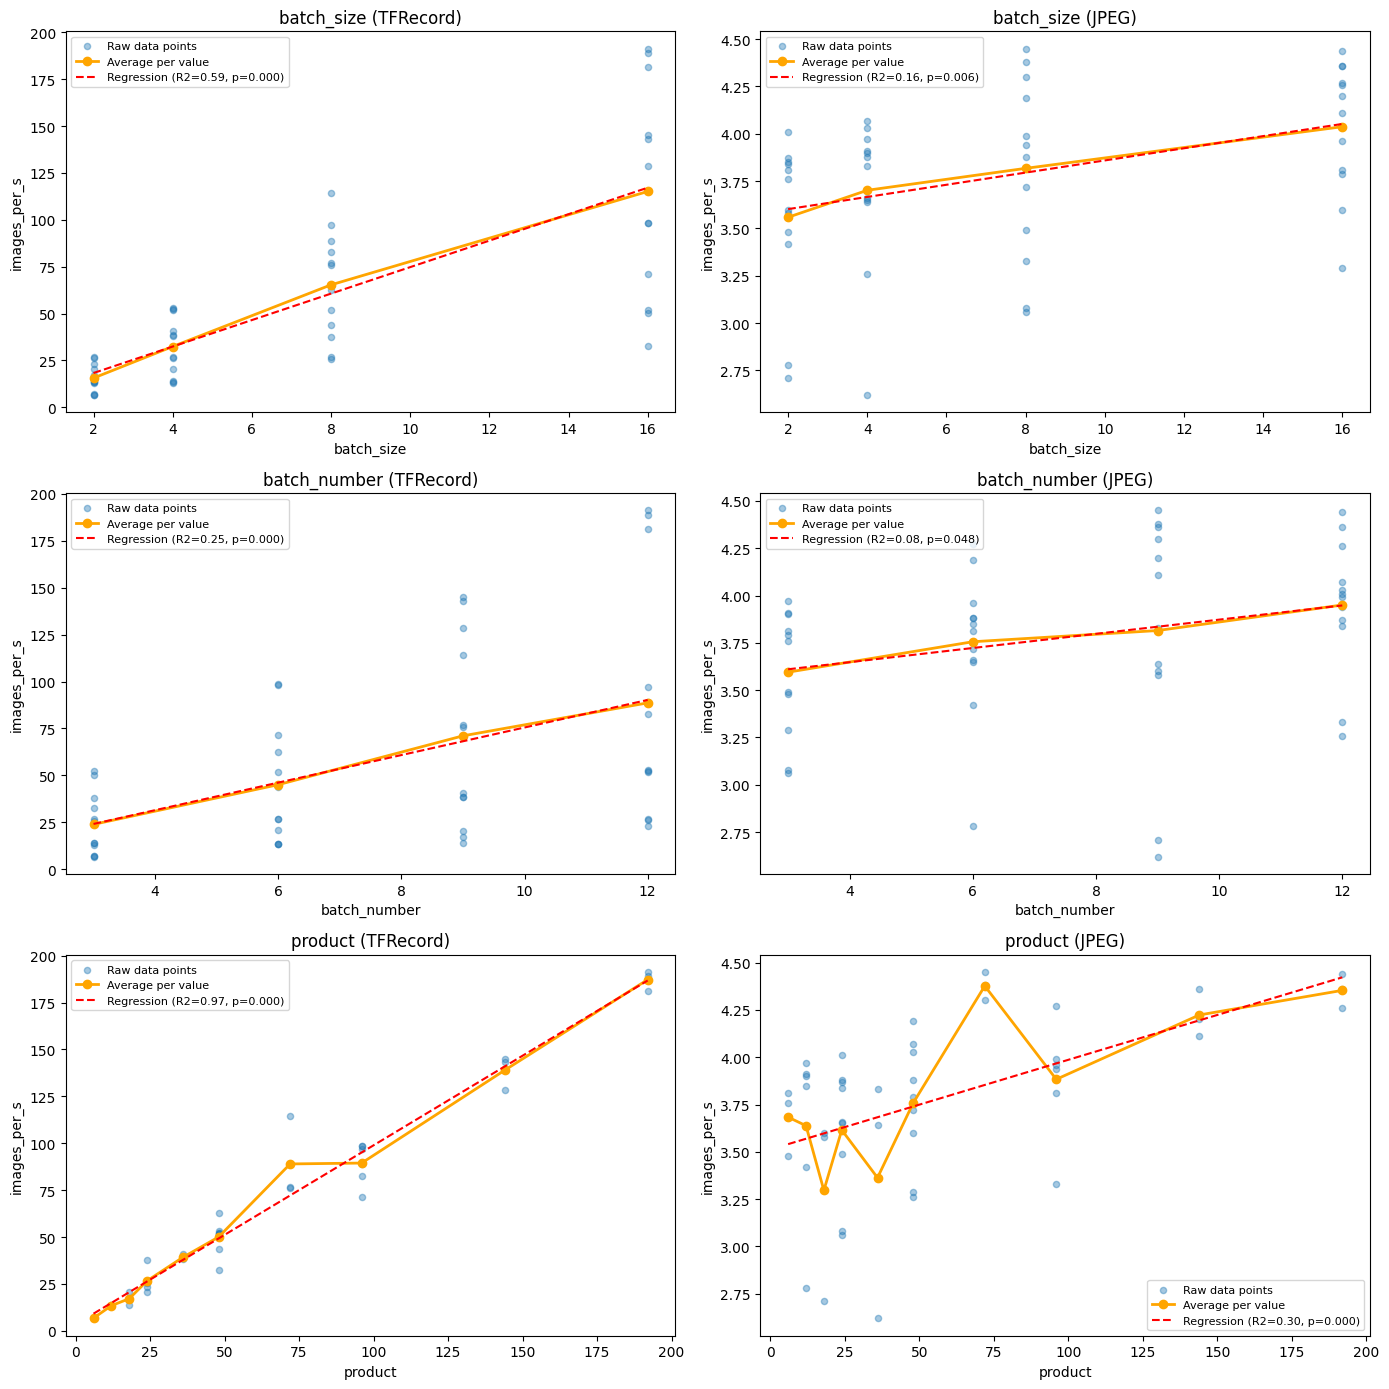

Plots saved to /content/task2d_plots.png


In [ ]:
import scipy.stats as stats
import matplotlib.pyplot as plt
import numpy as np

# This list collects regression statistics for each parameter-format plotted.
# It is subsequently used to construct the regression output table in Task 2d(iv).
regression_rows = []

def plot_param(ax, df, x_col, y_col, fmt_label):
    # Generates a single subplot for a specified parameter and data format.
    # Includes the raw data scatter, the mean value for each parameter setting, and the linear regression fit.
    # Returns regression statistics for inclusion in the output summary table.

    x = df[x_col].values.astype(float)
    y = df[y_col].values.astype(float)

    # Scatter plot of all individual measurements for visualising data distribution and variability.
    ax.scatter(x, y, alpha=0.4, s=20, label='Raw data points')

    # Plot of the average images per second for each unique parameter value, as required in the marking criteria.
    avg = df.groupby(x_col)[y_col].mean()
    ax.plot(
        avg.index.astype(float),
        avg.values,
        'o-',
        color='orange',
        linewidth=2,
        label='Average per value'
    )

    # Fit a linear regression to the raw data.
    slope, intercept, r_val, p_val, _ = stats.linregress(x, y)
    x_line = np.linspace(x.min(), x.max(), 100)
    ax.plot(
        x_line,
        slope * x_line + intercept,
        color='red',
        linestyle='--',
        label='Regression (R2={:.2f}, p={:.3f})'.format(r_val**2, p_val)
    )

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    ax.set_title('{} ({})'.format(x_col, fmt_label))
    ax.legend(fontsize=8)

    # Output collected regression statistics for summary table construction.
    return slope, intercept, r_val**2, p_val

# The parameters for analysis are specified by the assessment criteria.
params_to_plot = [
    ('batch_size',   'images_per_s'),
    ('batch_number', 'images_per_s'),
    ('product',      'images_per_s'),
]

# Create the required grid of subplots: three rows by two columns.
fig, axes = plt.subplots(3, 2, figsize=(14, 14))

for row_i, (x_col, y_col) in enumerate(params_to_plot):
    for col_i, (df, label) in enumerate([(df_tfrec, 'TFRecord'), (df_jpg, 'JPEG')]):
        slope, intercept, r2, p = plot_param(
            axes[row_i][col_i], df, x_col, y_col, label
        )
        regression_rows.append({
            'parameter': x_col,
            'format':    label,
            'slope':     round(slope, 4),
            'intercept': round(intercept, 4),
            'R2':        round(r2, 4),
            'p_value':   round(p, 4),
        })

plt.tight_layout()
plt.savefig('/content/task2d_plots.png', dpi=120)
plt.show()
print("Plots saved to /content/task2d_plots.png")

#### **2d(iv): Regression output table**

The table below lists the linear regression statistics for each parameter and
each file format. The brief requires regression to be performed separately for
TFRecord and JPEG cases and the results to be listed explicitly.

**Columns:**
- parameter: the independent variable (batch_size, batch_number, or product)
- format: TFRecord or JPEG
- slope: the regression coefficient, indicating the rate of change in images/s
- intercept: the regression intercept
- R2: coefficient of determination, indicating how well the linear model fits
- p_value: statistical significance of the slope

In [ ]:
# Assemble the regression statistics collected during 2d(iii) plotting

df_regression = pd.DataFrame(regression_rows)
print("Regression output table:")
print(df_regression.to_string(index=False))

Regression output table:
   parameter   format  slope  intercept     R2  p_value
  batch_size TFRecord 7.0585     4.1836 0.5911   0.0000
  batch_size     JPEG 0.0321     3.5379 0.1550   0.0056
batch_number TFRecord 7.3478     2.0138 0.2507   0.0003
batch_number     JPEG 0.0375     3.4979 0.0824   0.0478
     product TFRecord 0.9551     3.3968 0.9688   0.0000
     product     JPEG 0.0047     3.5124 0.3015   0.0001


#### **2d) Discussion Questions**

### **Q1: Discuss the implications of this result for applications like large-scale machine learning. Keep in mind that cloud data may be stored in distant physical locations. Use the numbers provided in the PDF latency-numbers document available on Moodle or here for your arguments:**

The speed test outcomes, which reached over 100 images per second on average for the largest TFRecord configurations, with individual data points exceeding 180 images per second, demonstrate that network capacity and bucket throughput, rather than local CPU power, form the primary bottlenecks for data retrieval. This has significant implications for large scale machine learning (ML), because training pipelines typically require ingesting the same substantial datasets repeatedly over numerous epochs. When data resides remotely in a Google Cloud Storage (GCS) bucket, each batch read imposes a network penalty proportional to the data size.

According to the reference "Latency numbers every programmer should know" (originally by Peter Norvig, data by Jeff Dean), reading 1 MB of data sequentially from memory takes a mere 250 microseconds, while a packet round-trip from California to the Netherlands takes 150 milliseconds. Even keeping operations within the same datacenter requires 0.5 milliseconds for a network round trip. Consequently, if an ML production environment spans multiple geographic regions, data ingestion speeds will suffer considerably from this cross-continent latency.

Additionally, the tests indicate that the TFRecord format achieves consistently higher throughput, performing approximately 28 times faster on average at larger batch sizes than processing raw JPEGs. In an ML context, TFRecords are highly advantageous because the images are already resized and compressed into a serialised format, reducing on-the-fly decoding costs and promoting efficient sequential reads. Sequential SSD reads operate at roughly 1 millisecond per MB, which is substantially faster than random access reads that fetch each image as a separate file. The result supports ahead-of-time data formatting (resizing and serialising images before training) as an important performance optimisation for large-scale training workloads, although this test does not separate the effect of the file format from that of the smaller resized images.

Lastly, implementing Spark caching mechanisms significantly diminishes the overhead of subsequent epochs by retaining the materialised Resilient Distributed Dataset (RDD) partitions directly in the workers' memory. Retrieving this cached data occurs at memory speeds of roughly 250 microseconds per MB, effectively eliminating the need for repeated GCS network calls. At scale, this transforms a training cycle that would otherwise be bottlenecked by continuous network I/O into a highly efficient, memory bound process.

### **Q2: How is the observed behaviour similar or different from what you'd expect from a single machine? Why would cloud providers tie throughput to capacity of disk resources?**

In an isolated single machine environment, data retrieval speeds are strictly bound by the performance of the local memory and physical storage subsystems. According to the reference "Latency numbers every programmer should know" (originally by Peter Norvig, data by Jeff Dean), sequentially reading 1 MB of data from a traditional hard disk takes 20 milliseconds, while the same read from a Solid State Drive (SSD) takes 1 millisecond. Because the data is stored locally, network latency is entirely eliminated. Consequently, single-machine throughput scales predictably and deterministically. Increasing batch sizes will proportionally increase the volume of data read until the hardware's local disk bandwidth ceiling is reached.

Conversely, executing these workflows in a distributed cloud ecosystem fundamentally alters the observed behaviour in two major ways. First, cloud execution introduces significant performance variance. Because cloud resources are multiplexed across numerous tenants, external factors such as network jitter, straggler nodes, and shared infrastructure contention create non-deterministic execution times across repetitions. Second, because the data resides remotely in a Google Cloud Storage (GCS) bucket, the assumption of data locality is broken. The ultimate throughput ceiling is dictated by network bandwidth rather than local disk speed. When multiple Spark workers concurrently fetch data, they can easily saturate the aggregate network capacity of the storage bucket before ever maxing out their own virtual disk limits.

Regarding storage provision, cloud providers deliberately bind virtual disk I/O throughput to the allocated capacity of the disk. Because virtual disks operate atop substantial, shared physical storage arrays, providers use this proportional allocation to maintain a fair and predictable multi-tenant resource model. Tenants who provision larger storage footprints are allocated proportionally higher I/O bandwidth, which prevents a single user from monopolising the underlying hardware and incentivises efficient resource provisioning. The Task 1d configuration applied this principle by distributing the 2000 GB of standard persistent disk evenly across the seven worker nodes (roughly 285 GB per node), aiming to maximise aggregate I/O bandwidth rather than concentrating that capacity on fewer machines. This principle directly benefits the speed tests in Task 2, as equipping workers with adequately sized disks ensures they possess the necessary I/O bandwidth to sustain rapid read and write rates for their local RDD memory caches.

### **Q3: By parallelising the speed test we are making assumptions about the limits of the bucket reading speeds. See here for more information. Discuss, what we need to consider in speed tests in parallel on the cloud, which bottlenecks we might be identifying, and how this relates to your results.**

Executing speed tests in parallel across various parameter combinations inherently relies on the assumption that the Google Cloud Storage (GCS) bucket possesses effectively unlimited read bandwidth. In reality, bucket egress capacity is a shared and finite resource. When multiple Spark workers simultaneously request data, they actively compete for this limited aggregate bandwidth. As a result, the measured throughput per worker naturally degrades as the number of concurrent readers increases. Therefore, the speed test does not measure the isolated computational efficiency of a single configuration. Instead, it measures the throughput of the system under conditions of heavy concurrent network access.

Consequently, the primary bottlenecks isolated in this experiment are not localized to individual worker CPU capacities or decoding times. Instead, they represent a composite ceiling defined by the GCS bucket's aggregate egress limits and the shared network bandwidth connecting the cluster to the storage layer.

This dynamic is best understood through underlying hardware speeds. As detailed in the reference "Latency numbers every programmer should know" (originally by Peter Norvig, data by Jeff Dean), a single network round-trip within the same datacenter requires approximately 0.5 milliseconds. This means that even without bandwidth contention, high-frequency remote reads are considerably expensive. For example, a configuration with a small overall data volume (e.g., a batch_size of 2 and batch_number of 3) forces the system to perform frequent, small sequential fetches, repeatedly incurring this 0.5 ms network penalty. Conversely, a larger parameter product (e.g., a batch_size of 16 and batch_number of 12) amortises this network round-trip latency across a much larger payload, theoretically yielding a higher images-per-second throughput.

However, as the empirical results demonstrate, particularly in the JPEG product plot where throughput rapidly hits a plateau, fluctuating between just 2.62 and 4.45 images per second regardless of the increasing data volume. Once the total volume of data requested per task grows large enough, the increased per-worker network demand compounds the contention effects. Ultimately, the results must be interpreted with the caveat that they characterize the saturation point of the entire distributed cloud architecture, not just the isolated performance of individual components.

### **Q4: Discuss to what extent linear modelling reflects the effects we are observing. Discuss what could be expected from a theoretical perspective and what can be useful in practice.**

Linear regression inherently assumes a constant, proportional relationship between predictor variables (such as batch_size, batch_number, or their product) and the target metric of images-per-second. However, in a distributed cloud architecture, relying on this assumption provides an incomplete picture of overall system throughput.

From a theoretical standpoint, data reading throughput is strictly constrained by a finite network bandwidth ceiling. While increasing the total volume of data per task initially yields performance gains by amortising the fixed costs of network round-trips over larger payloads, the throughput eventually plateaus or even declines once the aggregate bandwidth saturates. This phenomenon is explained by Amdahl's Law, which dictates that the maximum achievable speedup in a parallel system is bounded by its sequential bottlenecks (in this scenario, network initiation and serialisation overheads). Consequently, the actual performance curve exhibits diminishing returns that resemble a logarithmic or piecewise function, rather than a straight, continuous line.

As observed in the regression output table, the coefficient of determination (R2) varies considerably depending on the data format and parameter, reflecting this theoretical ceiling. For instance, the TFRecord product parameter exhibits a very high R2 of 0.97, indicating that the specific testing range happened to fall within the initial, pre-saturation portion of the performance curve where the relationship remains roughly linear. However, if these parameters were scaled upwards, the theoretical bandwidth ceiling would inevitably be hit and the linear fit would collapse. Conversely, the JPEG regression models yield low-to-moderate values (e.g., R2 = 0.30 for the product parameter and R2 = 0.08 for batch_number). This is not a failure of the model fit, but rather a reflection of genuine cloud non-determinism and notable bottlenecking. Shared cloud environments introduce significant variance through network jitter, resource contention, and straggler nodes, injecting noise that rigid deterministic models cannot accurately capture.

Despite its theoretical limitations at scale, linear regression remains practically useful as a first-order heuristic for identifying broad directional trends. For example, a statistically significant positive coefficient (demonstrated by a low p-value) reliably confirms that increasing batch parameters generally improves throughput within the tested bounds. Nevertheless, for production grade configuration selection, more sophisticated approaches are necessary to navigate the non-linear, non-convex nature of cloud performance. As demonstrated by the CherryPick system (Alipourfard et al., 2017), using non-parametric models like Bayesian Optimisation is far more effective in practice. Rather than attempting to fit a rigid global formula, CherryPick adaptively navigates this complex, noisy performance surface to identify optimal cloud configurations using only a minimal number of sample runs.

### ***Final cleanup***

In [ ]:
!gsutil -m rm -r $BUCKET/* # Empty your bucket
!gsutil rb $BUCKET # delete the bucket